In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import zipfile

with zipfile.ZipFile('/content/drive/MyDrive/UCI HAR Dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/UCI_HAR')

## 0 Data
### 0.1 Kaggle dataset

Because for the Task C Human Activity Recognition the Kaggle dataset already contains pre-computed features we use the raw version of the dataset from here:
https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

In [3]:
import os
for root, dirs, files in os.walk('/content/UCI_HAR'):
    print(root)

/content/UCI_HAR
/content/UCI_HAR/__MACOSX
/content/UCI_HAR/__MACOSX/UCI HAR Dataset
/content/UCI_HAR/__MACOSX/UCI HAR Dataset/test
/content/UCI_HAR/__MACOSX/UCI HAR Dataset/test/Inertial Signals
/content/UCI_HAR/__MACOSX/UCI HAR Dataset/train
/content/UCI_HAR/__MACOSX/UCI HAR Dataset/train/Inertial Signals
/content/UCI_HAR/UCI HAR Dataset
/content/UCI_HAR/UCI HAR Dataset/test
/content/UCI_HAR/UCI HAR Dataset/test/Inertial Signals
/content/UCI_HAR/UCI HAR Dataset/train
/content/UCI_HAR/UCI HAR Dataset/train/Inertial Signals


## Dataset Structure

The dataset is located at /content/UCI_HAR/UCI HAR Dataset and is organized as follows:

Inside of this folder we have the file activity_labels.txt that defines the 6 activity classes:
- 1: WALKING
- 2: WALKING_UPSTAIRS
- 3: WALKING_DOWNSTAIRS
- 4: SITTING
- 5: STANDING
- 6: LAYING

Also in this folder we have two subfolders: **train/** and **test/**<br>
Each of them contains:

**1. The raw data folder Inertial Signals/** with 9 .txt files, one per signal:
- body_acc_x.txt, body_acc_y.txt, body_acc_z.txt -> acceleration of the body without gravity (x, y, z axis)
- body_gyro_x.txt, body_gyro_y.txt, body_gyro_z.txt -> rotation of the phone (x, y, z axis)
- total_acc_x.txt, total_acc_y.txt, total_acc_z.txt -> total acceleration including gravity (x, y, z axis)

Each row in these files contains 128 values = 2.56 seconds * 50 readings per second, representing one 2.56-second window. Since an activity can last longer than 2.56 seconds, it can span multiple consecutive rows, where each row holds how the acceleration on that axis varied across the 2.56-second window.

For example the first row of body_acc_x_train.txt contains the 128 X-axis acceleration readings for sample 0 (STANDING), representing the first 2.56-second window of this activity. When we load all 9 signal files together, each sample becomes a table of shape (128 timesteps * 9 signals):

```
sample 0 (STANDING):
          body_acc_x  body_acc_y  body_acc_z  ...  total_acc_x  total_acc_y  total_acc_z
t1    ->  [  0.23,       0.01,       0.10,    ...     0.23,        0.01,        9.90    ]
t2    ->  [  0.22,       0.01,       0.11,    ...     0.22,        0.01,        9.88    ]
...
t128  ->  [  0.24,       0.02,       0.10,    ...     0.24,        0.02,        9.91    ]
```

So the full dataset has shape (n_samples, 128, 9) -> n_samples 2.56-second windows, each with 128 timesteps, each timestep with 9 signal values.

**2. y_train.txt / y_test.txt** (that are inside the train/ and test/ folders correspondingly) contains the activity label (1–6) for each row, telling us which activity the person was performing during that 2.56-second window


**Note:** The train/ and test/ folders also contain X_train.txt / X_test.txt which are pre-computed features we ignore them. The file features.txt contains the names of those 561 pre-computed features we ignore this too




In [4]:
for f in sorted(os.listdir('/content/UCI_HAR/UCI HAR Dataset')):
    print(f)

.DS_Store
README.txt
activity_labels.txt
features.txt
features_info.txt
test
train


In [5]:
print(open('/content/UCI_HAR/UCI HAR Dataset/activity_labels.txt').read())

1 WALKING
2 WALKING_UPSTAIRS
3 WALKING_DOWNSTAIRS
4 SITTING
5 STANDING
6 LAYING



In [6]:
for f in sorted(os.listdir('/content/UCI_HAR/UCI HAR Dataset/train')):
    print(f)

Inertial Signals
X_train.txt
subject_train.txt
y_train.txt


In [7]:
print("=== TRAIN Inertial Signals ===")
for f in sorted(os.listdir('/content/UCI_HAR/UCI HAR Dataset/train/Inertial Signals')):
    print(f)

print("\n=== TEST Inertial Signals ===")
for f in sorted(os.listdir('/content/UCI_HAR/UCI HAR Dataset/test/Inertial Signals')):
    print(f)

=== TRAIN Inertial Signals ===
body_acc_x_train.txt
body_acc_y_train.txt
body_acc_z_train.txt
body_gyro_x_train.txt
body_gyro_y_train.txt
body_gyro_z_train.txt
total_acc_x_train.txt
total_acc_y_train.txt
total_acc_z_train.txt

=== TEST Inertial Signals ===
body_acc_x_test.txt
body_acc_y_test.txt
body_acc_z_test.txt
body_gyro_x_test.txt
body_gyro_y_test.txt
body_gyro_z_test.txt
total_acc_x_test.txt
total_acc_y_test.txt
total_acc_z_test.txt


In [8]:
import numpy as np
import pandas as pd
import random
from sklearn.model_selection import train_test_split

In [9]:
dataset_path = '/content/UCI_HAR/UCI HAR Dataset'

# Activity labels
ACTIVITY_LABELS = {
    1: 'WALKING',
    2: 'WALKING_UPSTAIRS',
    3: 'WALKING_DOWNSTAIRS',
    4: 'SITTING',
    5: 'STANDING',
    6: 'LAYING'
}

# Load the 9 raw inertial signal files for a given split (train/test)
def load_signals(split):
    signals_path = f'{dataset_path}/{split}/Inertial Signals'
    signal_names = [
        'body_acc_x', 'body_acc_y', 'body_acc_z',
        'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
        'total_acc_x', 'total_acc_y', 'total_acc_z'
    ]
    signals = []
    for signal in signal_names:
        filename = f'{signals_path}/{signal}_{split}.txt'
        data = pd.read_csv(filename, sep=r'\s+', header=None).values
        signals.append(data)

    # result shape: (n_samples, 128, 9) -> (samples, timesteps, signals)
    # each sample contains 128 timesteps and each timestep has 9 signal values
    return np.stack(signals, axis=-1)

# Load activity labels for a given split
def load_labels(split):
    label_file = f'{dataset_path}/{split}/y_{split}.txt'
    # .values converts DataFrame to numpy array, .flatten() converts it from 2D (n_samples, 1) to 1D (n_samples,)
    return pd.read_csv(label_file, header=None).values.flatten()

# Load raw data from both splits
print("Loading raw data from both splits")
X_train_raw = load_signals('train')
y_train_raw = load_labels('train')

X_test_raw  = load_signals('test')
y_test_raw  = load_labels('test')

# Combine into one dataset before our own split
X_all = np.concatenate([X_train_raw, X_test_raw], axis=0)
y_all = np.concatenate([y_train_raw, y_test_raw], axis=0)

Loading raw data from both splits


In [10]:
# First split: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all,
    test_size=0.30,
    random_state=42,
    stratify=y_all
)

# Second split: 15% val, 15% test (50/50 of the 30% temp)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("DATA SPLITS:")
total = X_all.shape[0]
print(f"Training set   : {X_train.shape[0]} samples, represents {X_train.shape[0]/total*100:.1f}% of the whole dataset")
print(f"Validation set : {X_val.shape[0]} samples, represents {X_val.shape[0]/total*100:.1f}% of the whole dataset")
print(f"Test set       : {X_test.shape[0]} samples, represents {X_test.shape[0]/total*100:.1f}% of the whole dataset")

print("\n\nSamples per class per split:\n")

rows = []
for label_id, label_name in ACTIVITY_LABELS.items():
    training = np.sum(y_train == label_id)
    validation = np.sum(y_val == label_id)
    test = np.sum(y_test  == label_id)
    rows.append([label_name, training, validation, test])

df = pd.DataFrame(rows, columns=["Activity", "Train", "Val", "Test"])
display(df)

DATA SPLITS:
Training set   : 7209 samples, represents 70.0% of the whole dataset
Validation set : 1545 samples, represents 15.0% of the whole dataset
Test set       : 1545 samples, represents 15.0% of the whole dataset


Samples per class per split:



,Activity,Train,Val,Test
0,WALKING,1205,258,259
1,WALKING_UPSTAIRS,1081,232,231
2,WALKING_DOWNSTAIRS,984,211,211
3,SITTING,1244,266,267
4,STANDING,1334,286,286
5,LAYING,1361,292,291


In [11]:
print("DATASET OVERVIEW\n")
# X_all.shape = (n_samples, timesteps,  signals)
#                     [0]     [1]         [2]
print(f"Total samples       : {X_all.shape[0]}")
print(f"Timesteps per sample: {X_all.shape[1]}")
print(f"Number of signals   : {X_all.shape[2]}")
print(f"Number of classes   : {len(np.unique(y_all))}")
print(f"\n\nSamples per class:\n")

rows_overview = []
for label_id, label_name in ACTIVITY_LABELS.items():
    count = np.sum(y_all == label_id)
    rows_overview.append([label_id, label_name, count])

df_overview = pd.DataFrame(rows_overview, columns=["ID", "Activity", "Count"])
display(df_overview)

DATASET OVERVIEW

Total samples       : 10299
Timesteps per sample: 128
Number of signals   : 9
Number of classes   : 6


Samples per class:



,ID,Activity,Count
0,1,WALKING,1722
1,2,WALKING_UPSTAIRS,1544
2,3,WALKING_DOWNSTAIRS,1406
3,4,SITTING,1777
4,5,STANDING,1906
5,6,LAYING,1944


## Sub-question Q0.1

**Which metric becomes misleading in an imbalanced dataset ?**<br>
Accuracy becomes misleading when class imbalance exists. A model that always predicts the majority class would achieve a deceptively high accuracy while performing poorly on the minority classes

**What problem does imbalance cause during training ?**<br>
During training class imbalance causes the model to be biased toward the
majority class. This means the model rarely sees examples from minority
classes so it learns very little about them and tends to misclassify them

**What did we do about it ?**<br>
We applied stratify=y when splitting the data so that each subset
(train/val/test) reflects the same class proportions as the full dataset,
avoiding splits where a subset ends up with too many samples from the
majority class and very few (or none) from the minority classes. We also use F1-macro as our main evaluation metric instead of accuracy since F1-macro treats all classes equally regardless of their size

# 0.2 Personal Data

In [12]:
drive_path = '/content/drive/MyDrive/data'
local_path = '/content/my_raw_signals'

# create the local folder
os.makedirs(local_path, exist_ok=True)

# Process all zips in that folder
for zip_name in os.listdir(drive_path):
    # SKIP HIDDEN FILES AND NON ZIPS
    if zip_name.startswith('.') or not zip_name.endswith('.zip'):
        continue

    full_path = os.path.join(drive_path, zip_name)
    folder_name = zip_name.replace('.zip', '')
    destination = os.path.join(local_path, folder_name)


    with zipfile.ZipFile(full_path, 'r') as zip_ref:
        zip_ref.extractall(destination)
        print(f"Successfully unzipped: {zip_name}")


print("\nAll files are now in /content/my_raw_signals and ready for processing!")

Successfully unzipped: STANDING5.zip
Successfully unzipped: STANDING4.zip
Successfully unzipped: STANDING3.zip
Successfully unzipped: STANDING2.zip
Successfully unzipped: STANDING1.zip
Successfully unzipped: WALKING_UPSTAIRS1.zip
Successfully unzipped: WALKING_UPSTAIRS2.zip
Successfully unzipped: WALKING_UPSTAIRS3.zip
Successfully unzipped: WALKING_UPSTAIRS4.zip
Successfully unzipped: WALKING_UPSTAIRS5.zip
Successfully unzipped: WALKING_UPSTAIRS6.zip
Successfully unzipped: LAYING1.zip
Successfully unzipped: LAYING9.zip
Successfully unzipped: LAYING2.zip
Successfully unzipped: LAYING3.zip
Successfully unzipped: LAYING4.zip
Successfully unzipped: LAYING10.zip
Successfully unzipped: LAYING8.zip
Successfully unzipped: LAYING7.zip
Successfully unzipped: LAYING6.zip
Successfully unzipped: LAYING5.zip
Successfully unzipped: STANDING6.zip
Successfully unzipped: STANDING7.zip
Successfully unzipped: STANDING8.zip
Successfully unzipped: STANDING9.zip
Successfully unzipped: STANDING10.zip
Successf

In [13]:
from scipy import signal

# Visual representation of the recordings from the zip files
#   Time (s)   Acceleration x (m/s^2)   Acceleration y (m/s^2)   Acceleration z (m/s^2)   Absolute acceleration (m/s^2)
# 0   0.035          -2.065                   5.065                    6.745                    8.684
# 1   0.037          -2.043                   5.063                    6.757                    8.687
# 2   0.038          -2.024                   5.067                    6.795                    8.715
# 3   0.039          -2.012                   5.084                    6.850                    8.765
# 4   0.040          -1.993                   5.108                    6.903                    8.816
# ...

def process_all_collected_data(base_path):

    label_map = {
        'WALKING' : 1,
        'WALKING_UPSTAIRS' : 2,
        'STANDING' : 5,
        'LAYING' : 6
    }

    print("Processing files...")

    # Lists to collect all windows and labels from all recordings
    all_windows = []
    all_labels = []

    for folder in os.listdir(base_path):

        folder_path = os.path.join(base_path, folder)

        csv_path = os.path.join(folder_path, 'Raw Data.csv')

        if os.path.exists(csv_path):

          df = pd.read_csv(csv_path)

          times = df['Time (s)'].values

          activity = folder.rstrip('0123456789').upper()
          label = label_map[activity]

          # Trim 4s from start and end of the recording is noise
          keep_times = (times >= times[0] + 4.0) & (times <= times[-1] - 4.0)

          df = df[keep_times].reset_index(drop=True)

          # Extract 3 axes together as a 2D array (n_rows, 3)
          # for example
          #         col0 (acc_x)   col1 (acc_y)   col2 (acc_z)
          # row 0  [  -0.971,         2.507,         6.474  ]
          # row 1  [  -0.954,         2.536,         6.381  ]
          # row 2  [  -0.947,         2.581,         6.307  ]
          # ...
          # row 22886 [ -0.918,       2.962,        12.492  ]
          raw_acc = df[['Acceleration x (m/s^2)',
                        'Acceleration y (m/s^2)',
                        'Acceleration z (m/s^2)']].values / 9.80665  # convert m/s^2 to g units

          # WHY WE DIVIDE BY 9.80665 ?
          #
          # Before adding this line when running chapter 3.1 the model predicted every single sample
          # as LAYING regardless of the true activity. The accuracy was only 19%
          # which is exactly 87/458 i.e. the proportion of LAYING samples in the
          # personal data meaning the model learned nothing useful.
          #
          # After investigating the results I found the root cause of the problem:
          # a units mismatch between the UCI HAR dataset and our dataset.
          #
          # Specifically:
          #
          # UCI HAR dataset total_acc value ranges:
          #   total_acc_x -> min: -0.4666  max: 2.1976
          #   total_acc_y -> min: -1.5882  max: 1.2173
          #   total_acc_z -> min: -1.6396  max: 1.2814
          #
          # Our own dataset total_acc value ranges:
          #   total_acc_x -> min: -4.7125  max: 15.7172
          #   total_acc_y -> min: -14.3206  max:  7.3736
          #   total_acc_z -> min: -8.4130  max: 21.2388
          #
          # The scales are completely different as you can see.
          #
          # Reading the README.txt of the UCI HAR dataset, it explicitly states:
          #   "The units used for the accelerations (total and body) are g's
          #    (gravity of earth -> 9.80665 m/seg2)"
          #
          # While our Phyphox App records in m/s^2 as shown in the CSV column names:
          #   Acceleration x (m/s^2)
          #   Acceleration y (m/s^2)
          #   Acceleration z (m/s^2)
          #
          # Since 1g = 9.80665 m/s^2, dividing our values by 9.80665 converts
          # them from m/s^2 to g units i.e. the same scale as UCI HAR.
          # After this conversion the accuracy improved from 19% to 47%
          # confirming that the units mismatch was the primary cause.

          times = df['Time (s)'].values

          # duration it has the seconds of the clean activity after trimming
          duration = times[-1] - times[0]

          # duration * 50 = how many samples we need at 50 Hz
          # e.g. 27.4 seconds * 50 samples per second = 1371 samples
          num_samples_target = int(np.round(duration * 50))

          # Take all the table raw_acc and compress it down to (num_samples_target, 3) at 50 Hz
          resampled_acc = signal.resample(raw_acc, num_samples_target)

          # Slice into 128 sample windows (UCI HAR format)
          WINDOW_SIZE = 128
          n_windows = len(resampled_acc) // WINDOW_SIZE

          for i in range(n_windows):

              # Get 128 samples for this window
              start = i * WINDOW_SIZE
              end = start + WINDOW_SIZE

              # Pack into (128, 9) shape to match UCI HAR format
              window  = np.zeros((WINDOW_SIZE, 9))
              window[:, 6] = resampled_acc[start:end, 0]  # total_acc_x
              window[:, 7] = resampled_acc[start:end, 1]  # total_acc_y
              window[:, 8] = resampled_acc[start:end, 2]  # total_acc_z

              all_windows.append(window)
              all_labels.append(label)

    # Convert to numpy arrays
    X_own = np.array(all_windows) # (total_windows, 128, 9)
    y_own = np.array(all_labels) # (total_windows,)

    return X_own, y_own

X_own_raw, y_own_raw = process_all_collected_data(local_path)

print(f"\nDone! Total windows created : {X_own_raw.shape[0]}")
print(f"Shape of X_own_raw : {X_own_raw.shape}")
print(f"Shape of y_own_raw : {y_own_raw.shape}")

Processing files...

Done! Total windows created : 458
Shape of X_own_raw : (458, 128, 9)
Shape of y_own_raw : (458,)


In [14]:
# Basic statistics per activity class
print("\nPersonal Data Statistics:")
print(f"Total windows    : {len(y_own_raw)}")
print(f"Total recordings : 40\n")

print(f"{'Activity':<17} {'Recordings':>12} {'Windows':>10}")
print("-" * 45)
for label_id, label_name in ACTIVITY_LABELS.items():
    count = np.sum(y_own_raw == label_id)
    if count > 0:
        print(f"{label_name:<17} {'10':>12} {count:>10}")


Personal Data Statistics:
Total windows    : 458
Total recordings : 40

Activity            Recordings    Windows
---------------------------------------------
WALKING                     10        148
WALKING_UPSTAIRS            10        140
STANDING                    10         83
LAYING                      10         87


## Sub-question Q0.2

**Explicitly record the criteria you followed for the annotation**

Each recording was manually labeled based on the activity performed during the recording. The label was assigned by naming the folder with the activity name during data collection:

- WALKING          : walked at a steady pace on a flat surface for ~20 seconds
- WALKING_UPSTAIRS : walked up stairs trying to maintain a steady pace for ~20 seconds
- STANDING         : stood still for ~20 seconds
- LAYING           : laid down flat on my bed for ~20 seconds

<br>

**Under what conditions were the data collected**

- Device   : Samsung A52s
- App      : Phyphox App
- Position : phone held in right hand with the hand pointing downward
- Location per activity:
> WALKING          : outside on a flat surface in a quiet environment to maintain a steady pace <br>
> WALKING_UPSTAIRS : outside on a continuous staircase in a quiet environment trying to maintain a steady pace <br>
> STANDING         : inside at home in a quiet environment <br>
> LAYING           : lying flat on a bed at home in a quiet environment

10 recordings per activity * 4 activities = 40 total recordings <br>
Each recording lasted approximately ~20 seconds before trimming <br>
After trimming 4s from start and end of the recording to remove the noise we have ~12 seconds of clean activity action

<br>

**What biases could the way you collected the data introduce ?**

1) First and most importantly as we can see from the statistics per activity class:
```
Activity                  Windows
---------------------------------------------
WALKING                     148
WALKING_UPSTAIRS            140
STANDING                     83
LAYING                       87
```

The dataset is imbalanced i.e. WALKING and WALKING_UPSTAIRS have too many windows compared to STANDING and LAYING. This happened because for STANDING and LAYING I used a timer so each recording lasted  ~20 seconds. For WALKING and WALKING_UPSTAIRS I was outside without a clock and counted internally, which led to longer recordings. At that time I didn't think this would cause a problem i.e. that the dataset would be imbalanced (sorry about that).
<br> <br>
One solution to make my dataset balanced would be to trim more seconds from the WALKING and WALKING_UPSTAIRS recordings. However I am curious how my pre-trained model will perform on this imbalanced dataset in Section 3.1, so I intentionally left things as they are.

2) Single person -> I recorded only my own walking style with my own body weight. Since I am a tall person (2 meters above average height) I walk differently from an average person. Also I am 26 years old so I walk at a different pace compared to older people. Therefore the data does not reflect the diversity of ages, heights, weights and walking styles of the real population.

3) Single phone position -> the phone was always held in my right hand pointing downward. This is because when the phone screen turned off, the app stopped recording, so I had to keep the screen on which meant I could not put it in my pocket. In real life people carry phones in their pockets which produce different sensor readings.


4) Single location -> all recordings were made in the same location (same staircase for WALKING_UPSTAIRS and the same flat surface for WALKING) and in a quiet environment to maintain a steady pace. However some recordings were made when I was tired which adds some diversity to the data. In real life people walk on different surfaces, different staircases and in different environments which would produce different sensor readings.

5) Single phone -> only my own device with its own sensor. The results may not generalize to other phones since different devices have different sensors with different sensitivity.

**Is there homogeneity that does not reflect the diversity of the real population ?**

Yes the data is highly homogeneous because of all the biases mentioned above. All of these together mean that the dataset only captures one very specific combination of person and does not reflect the diversity of the real population in terms of different ages, heights, body weights, walking styles, phone types, phone positions and recording environments.

## 1. Feature Extraction

### 1.1 Feature Extraction

In [15]:
import numpy as np

# Our dataset has shape (n_samples, 128, 9)

# example:

# sample 0 (STANDING):

#          col0       col1       col2       col3       col4       col5       col6       col7       col8
#       body_acc_x body_acc_y body_acc_z body_gyro_x body_gyro_y body_gyro_z total_acc_x total_acc_y total_acc_z
# t1  [  0.23,      0.01,      0.10,      0.002,      0.001,     -0.003,      0.23,       0.01,       9.90  ]
# t2  [  0.22,      0.01,      0.11,      0.001,      0.002,     -0.002,      0.22,       0.01,       9.88  ]
# ...
# t128[ 0.24,       0.02,      0.10,      0.003,      0.001,     -0.001,      0.24,       0.02,       9.91  ]

# So we use total_acc which is total acceleration including gravity (indices 6,7,8)
# index 6 = total_acc_x
# index 7 = total_acc_y
# index 8 = total_acc_z



# Code from here:
# https://dsp.stackexchange.com/questions/78355/how-to-extract-the-dominant-frequency-from-the-audio-wav-file-using-numpy
def extract_peak_frequency(axis, sampling_rate):

    fft_data = np.fft.fft(axis)
    freqs = np.fft.fftfreq(len(axis))

    peak_coefficient = np.argmax(np.abs(fft_data))
    peak_freq = freqs[peak_coefficient]

    return abs(peak_freq * sampling_rate)

# The function below
# Input : dataset of shape (n_samples, 128, 9)
# Output : feature matrix of shape (n_samples, 20)
# Feature breakdown:
#  - mean, std, min, max for total_acc_x, y, z    -> 12 features
#  - magnitude mean + std                         ->  2 features
#  - zero crossing rate for total_acc_x, y, z     ->  3 features
#  - FFT dominant frequency for total_acc_x, y, z ->  3 features
#
#  TOTAL                                          -> 20 features
def extract_basic_features(data):

    features_list = []

    for i in range(data.shape[0]):
        sample = data[i]  # shape (128, 9)
        current_features  = []

        # total_acc axes
        total_acc_x = sample[:, 6]  # take all 128 rows from column 6 which referring to total_acc_x
        total_acc_y = sample[:, 7]  # take all 128 rows from column 7 which referring to total_acc_y
        total_acc_z = sample[:, 8]  # take all 128 rows from column 8 which referring to total_acc_z

        # Part Statistics per axis: mean, std, min, max (3 axes * 4 stats = 12 features)
        for axis in [total_acc_x, total_acc_y, total_acc_z]:
            current_features.append(np.mean(axis))
            current_features.append(np.std(axis))
            current_features.append(np.min(axis))
            current_features.append(np.max(axis))


        # Part Magnitude (2 features)
        mag = np.sqrt(total_acc_x**2 + total_acc_y**2 + total_acc_z**2)
        current_features.append(np.mean(mag))
        current_features.append(np.std(mag))


        # Part 3 Zero Crossing Rate per axis (3 features)
        for axis in [total_acc_x, total_acc_y, total_acc_z]:
            # Center around mean (not zero) as the assignment requires crossing
            # of the mean value not zero
            centered = axis - np.mean(axis)


            # Step 1: np.sign(centered)
            # Converts each value to its sign:
            #   negative == -1
            #   zero ==  0
            #   positive == +1

            # Step 2: np.diff(...)
            # Subtracts each value from the next one:
            #   Same sign -> result is 0 -> no change
            #   Different sign -> result is not 0 -> crossing happened!

            # Step 3: != 0
            # A non-zero difference means the sign changed between two consecutive
            # values which means the signal crossed the mean at that point

            # Step 4: np.sum(...)
            # Counts the total number of crossings

            # Step 5: / len(centered)
            # Normalizes by the total length of the signal
            # Without normalization a longer signal would always have more crossings
            # just because it has more data points not because it oscillates more
            # This makes the result comparable between signals of different lengths

            zero_crossing_rate = np.sum(np.diff(np.sign(centered)) != 0) / len(centered)
            current_features.append(zero_crossing_rate)

        # Part 4 FFT dominant frequency per axis (3 features)
        # Distinguishes walking (~2 Hz) from running (~3 Hz)
        sampling_rate = 50  # UCI HAR dataset is recorded at 50 Hz
        for axis in [total_acc_x, total_acc_y, total_acc_z]:
            dominant_freq = extract_peak_frequency(axis, sampling_rate)
            current_features.append(dominant_freq)

        # Total: 12 + 2 + 3 + 3 = 20 features per sample
        features_list.append(current_features)

    return np.array(features_list)

# Apply to all splits
print("Extracting basic features...")
X_train_features = extract_basic_features(X_train)
X_val_features = extract_basic_features(X_val)
X_test_features = extract_basic_features(X_test)

print(f"X_train_features shape: {X_train_features.shape}") # (n_samples, 20)
print(f"X_val_features shape  : {X_val_features.shape}") # (n_samples, 20)
print(f"X_test_features shape : {X_test_features.shape}") # (n_samples, 20)

Extracting basic features...
X_train_features shape: (7209, 20)
X_val_features shape  : (1545, 20)
X_test_features shape : (1545, 20)


## Sub-question Q1.1

Which additional features did you implement (at least one) ? <br>
What hypothesis led you to choose them ?

One additional feature was implemented: the FFT dominant frequency

**FFT dominant frequency:**
We have that different activities produce different frequencies.
Specifically walking (\~2 Hz) and running (\~3 Hz) have characteristic frequencies that the FFT can detect

**Based on the histograms and the correlation matrix (§1.3), do they appear to differentiate the classes ?**

No. The histograms and correlation matrix in §1.3 show that fft_dominant_freq_x, fft_dominant_freq_y and fft_dominant_freq_z have almost complete overlap across all 6 activities and provide no meaningful separation.


### 1.2 Feature Preprocessing

In [16]:
import pandas as pd


feature_names = [
    'total_acc_x_mean', 'total_acc_x_std', 'total_acc_x_min', 'total_acc_x_max',
    'total_acc_y_mean', 'total_acc_y_std', 'total_acc_y_min', 'total_acc_y_max',
    'total_acc_z_mean', 'total_acc_z_std', 'total_acc_z_min', 'total_acc_z_max',
    'magnitude_mean', 'magnitude_std',
    'zero_crossing_rate_x', 'zero_crossing_rate_y', 'zero_crossing_rate_z',
    'fft_dominant_freq_x', 'fft_dominant_freq_y', 'fft_dominant_freq_z'
]


df_train = pd.DataFrame(X_train_features, columns=feature_names)
df_val = pd.DataFrame(X_val_features, columns=feature_names)
df_test = pd.DataFrame(X_test_features, columns=feature_names)


print("Checking for NaN in the dataframes")
print("\nTrain dataframe:")
print(df_train.isnull().sum())

print("\nValidation dataframe:")
print(df_val.isnull().sum())

print("\nTest dataframe:")
print(df_test.isnull().sum())

Checking for NaN in the dataframes

Train dataframe:
total_acc_x_mean        0
total_acc_x_std         0
total_acc_x_min         0
total_acc_x_max         0
total_acc_y_mean        0
total_acc_y_std         0
total_acc_y_min         0
total_acc_y_max         0
total_acc_z_mean        0
total_acc_z_std         0
total_acc_z_min         0
total_acc_z_max         0
magnitude_mean          0
magnitude_std           0
zero_crossing_rate_x    0
zero_crossing_rate_y    0
zero_crossing_rate_z    0
fft_dominant_freq_x     0
fft_dominant_freq_y     0
fft_dominant_freq_z     0
dtype: int64

Validation dataframe:
total_acc_x_mean        0
total_acc_x_std         0
total_acc_x_min         0
total_acc_x_max         0
total_acc_y_mean        0
total_acc_y_std         0
total_acc_y_min         0
total_acc_y_max         0
total_acc_z_mean        0
total_acc_z_std         0
total_acc_z_min         0
total_acc_z_max         0
magnitude_mean          0
magnitude_std           0
zero_crossing_rate_x    0
z

In [17]:
print("Checking for Inf in the dataframes")
print("\nTrain dataframe:")
print(np.isinf(df_train).sum())

print("\nValidation dataframe:")
print(np.isinf(df_val).sum())

print("\nTest dataframe:")
print(np.isinf(df_test).sum())

Checking for Inf in the dataframes

Train dataframe:
total_acc_x_mean        0
total_acc_x_std         0
total_acc_x_min         0
total_acc_x_max         0
total_acc_y_mean        0
total_acc_y_std         0
total_acc_y_min         0
total_acc_y_max         0
total_acc_z_mean        0
total_acc_z_std         0
total_acc_z_min         0
total_acc_z_max         0
magnitude_mean          0
magnitude_std           0
zero_crossing_rate_x    0
zero_crossing_rate_y    0
zero_crossing_rate_z    0
fft_dominant_freq_x     0
fft_dominant_freq_y     0
fft_dominant_freq_z     0
dtype: int64

Validation dataframe:
total_acc_x_mean        0
total_acc_x_std         0
total_acc_x_min         0
total_acc_x_max         0
total_acc_y_mean        0
total_acc_y_std         0
total_acc_y_min         0
total_acc_y_max         0
total_acc_z_mean        0
total_acc_z_std         0
total_acc_z_min         0
total_acc_z_max         0
magnitude_mean          0
magnitude_std           0
zero_crossing_rate_x    0
z

In [18]:
from scipy import stats

# The Z-score measures how far a value is from the mean in terms of standard deviations
# We use it to detect outliers in our feature matrix np.abs takes the absolute value
# so we only care about how far a value is from the mean not the direction
z_scores = np.abs(stats.zscore(X_train_features))

# We check z > 3 because a value more than 3 standard deviations away from the mean is considered an outlier
# This threshold is a widely used rule in statistics:
# z = 0 to 1 -> normal
# z = 1 to 2 -> slightly unusual
# z = 2 to 3 -> unusual
# z > 3      -> likely outlier
outlier_count = (z_scores > 3).sum()
print(f"Number of outliers (|z| > 3): {outlier_count}")

Number of outliers (|z| > 3): 453


In [19]:
total_values = X_train_features.shape[0] * X_train_features.shape[1]
outlier_percentage = (outlier_count / total_values) * 100
print(f"Total values checked: {total_values}")
print(f"Outlier percentage: {outlier_percentage:.2f}%")

Total values checked: 144180
Outlier percentage: 0.31%


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data and transform it
X_train_scaled = scaler.fit_transform(X_train_features)

# Transform val and test using the same statistics learned from train
X_val_scaled  = scaler.transform(X_val_features)
X_test_scaled = scaler.transform(X_test_features)

## Sub-question Q1.2


How did you handle the missing values (if any) ? <br> <br>
For the missing values we see that we didn't have NaN or Inf values in any of the train set, validation set and test set

<br> <br>


Justify how you chose the normalization method <br> <br>
For the normalization part we chose the StandardScaler because our 20 features have very different scales: total_acc_x_mean ranges between -0.37 and 1.06, zero_crossing_rate ranges between 0 and 1, while fft_dominant_freq ranges between 0 and 50 Hz. Without normalization distance based algorithms like k-NN and SVM would be dominated by features with larger values simply because they are numerically bigger not because they are more importan. <br>

We did not choose MinMaxScaler because it is sensitive to values outside
the range seen in training data and accelerometer data in real life can
always have unexpected values, which would produce scaled values outside
the [0,1] range and hurt model performance <br>

We did not choose RobustScaler because it is designed for data with many
outliers. We verified this by checking Z-scores across all features and we got that only 453 values out of 144,180 (0.31%) had |z| > 3 confirming that outliers are extremely rare in the UCI HAR dataset


### 1.3 Exploration

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


def plot_feature_histogram(feature_name, feature_names, X_scaled, y, activity_labels):

    colors = [
      '#e6194b',
      '#000000',
      '#FFD700',
      '#3cb44b',
      '#42d4f4',
      '#f032e6',
    ]

    feat_idx = feature_names.index(feature_name)

    fig, ax = plt.subplots(figsize=(8, 4))

    for label_idx, label_id in enumerate(sorted(activity_labels.keys())):
        mask = (y == label_id)
        ax.hist(
            X_scaled[mask, feat_idx],
            bins=30,
            density=True,
            histtype='step',
            linewidth=1.5,
            color=colors[label_idx],
            label=activity_labels[label_id]
        )

    ax.set_title(feature_name, fontsize=12)
    ax.set_xlabel('Scaled value', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

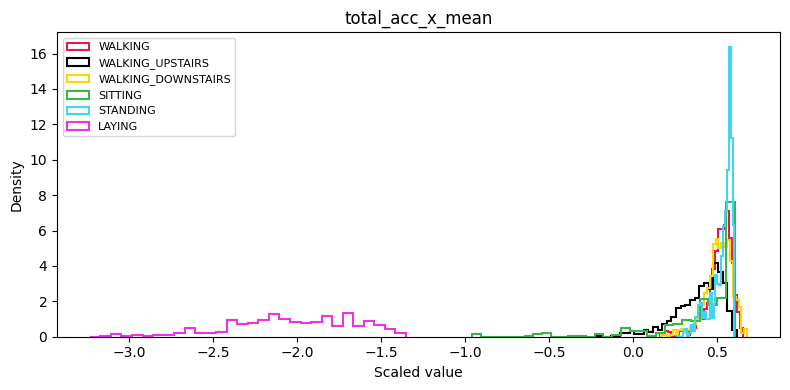

In [22]:
plot_feature_histogram('total_acc_x_mean', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

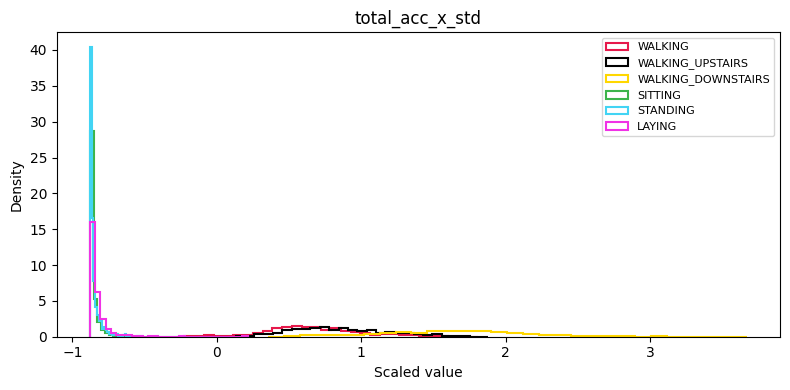

In [23]:
plot_feature_histogram('total_acc_x_std', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

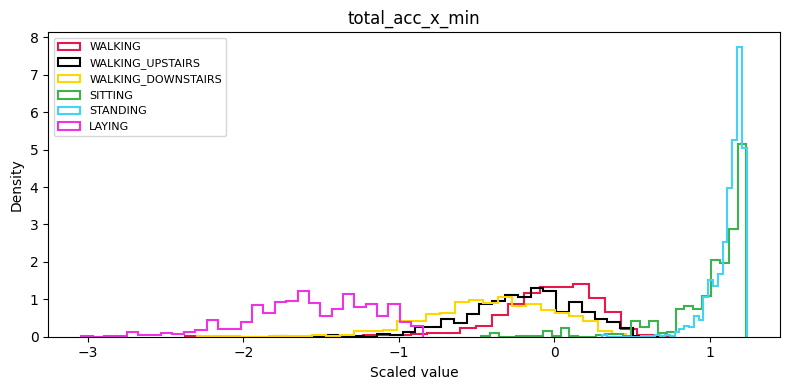

In [24]:
plot_feature_histogram('total_acc_x_min', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

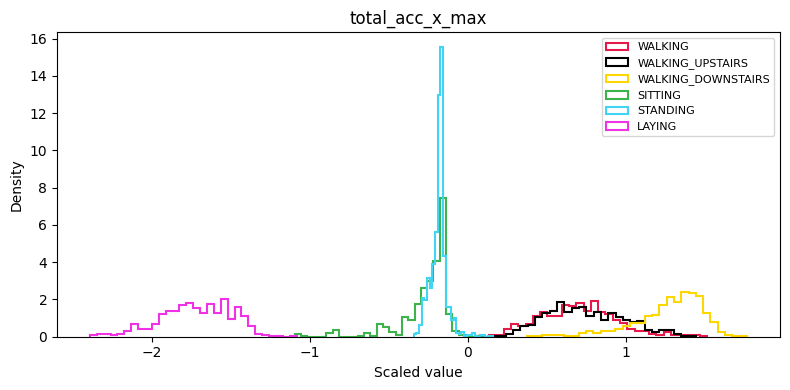

In [25]:
plot_feature_histogram('total_acc_x_max', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

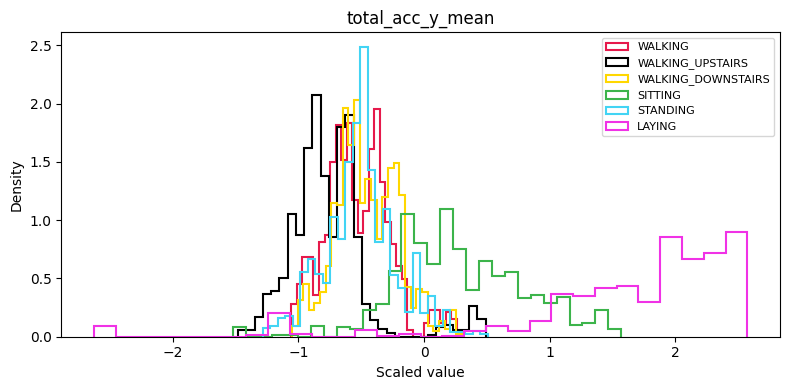

In [26]:
plot_feature_histogram('total_acc_y_mean', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

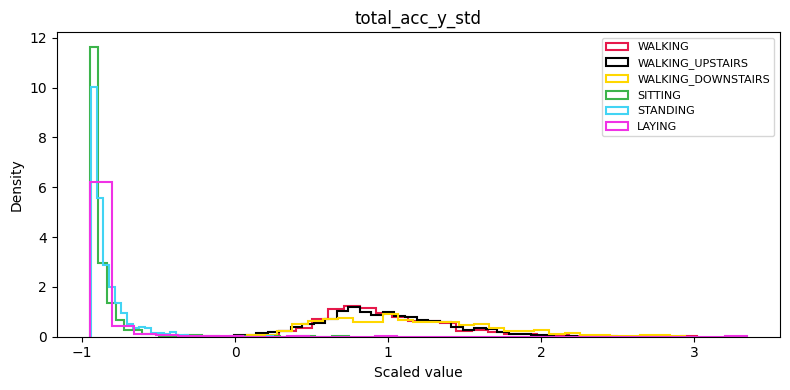

In [27]:
plot_feature_histogram('total_acc_y_std', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

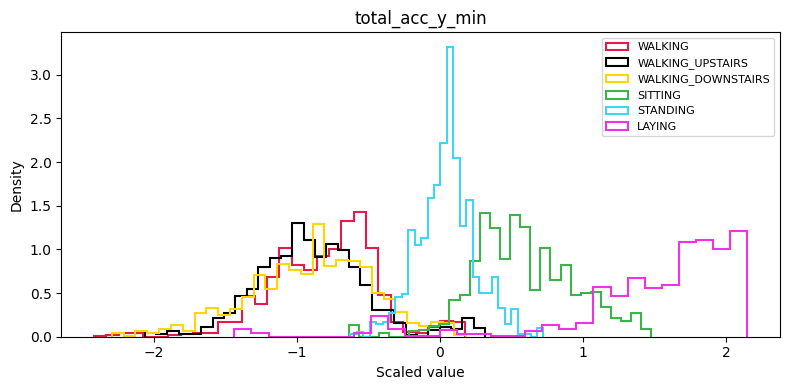

In [28]:
plot_feature_histogram('total_acc_y_min', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

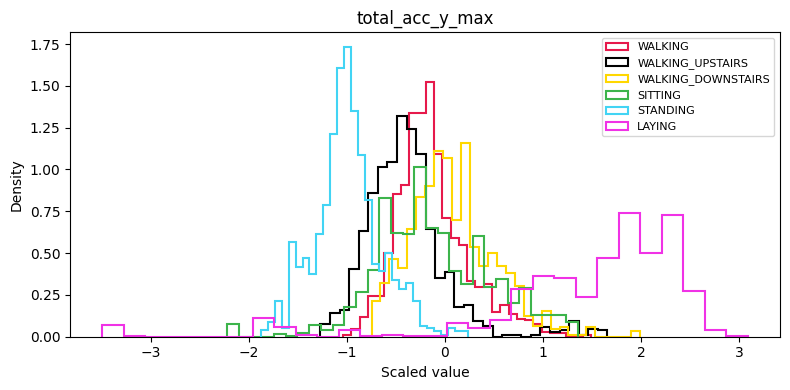

In [29]:
plot_feature_histogram('total_acc_y_max', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

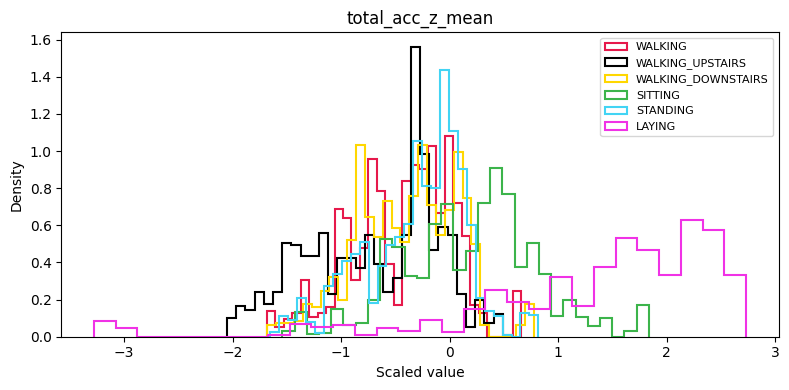

In [30]:
plot_feature_histogram('total_acc_z_mean', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

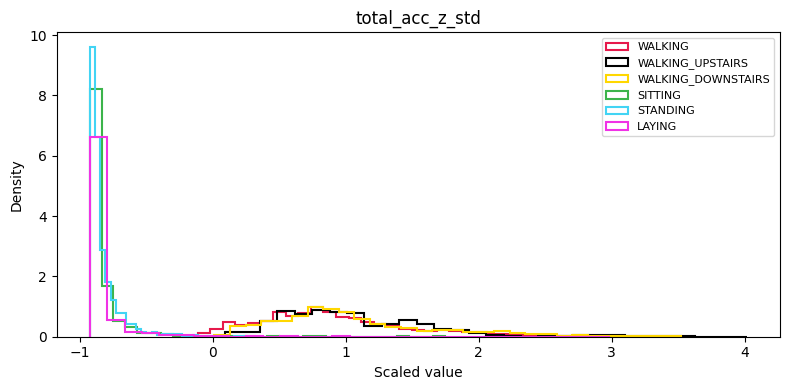

In [31]:
plot_feature_histogram('total_acc_z_std', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

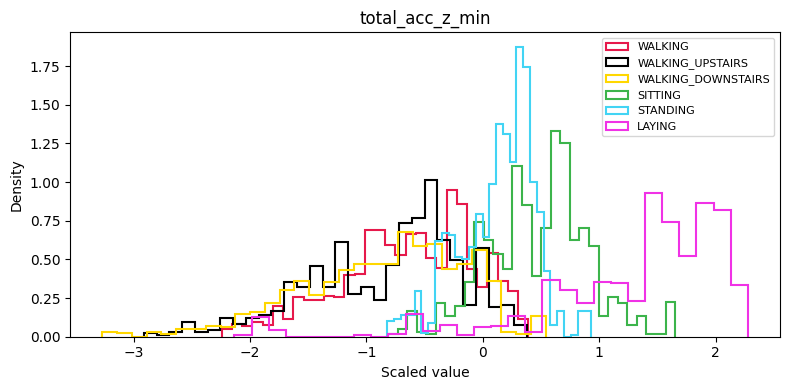

In [32]:
plot_feature_histogram('total_acc_z_min', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

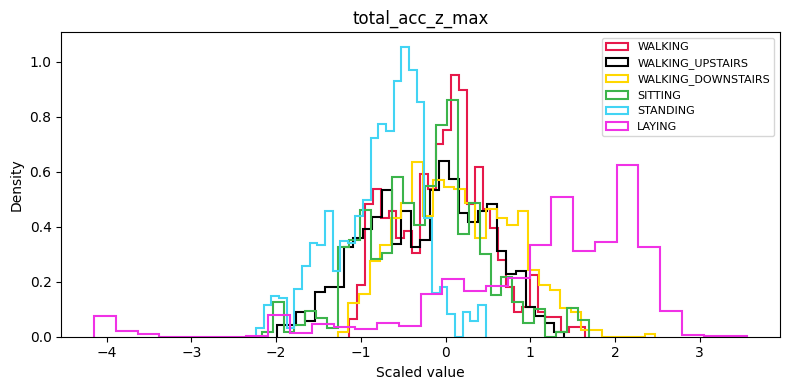

In [33]:
plot_feature_histogram('total_acc_z_max', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

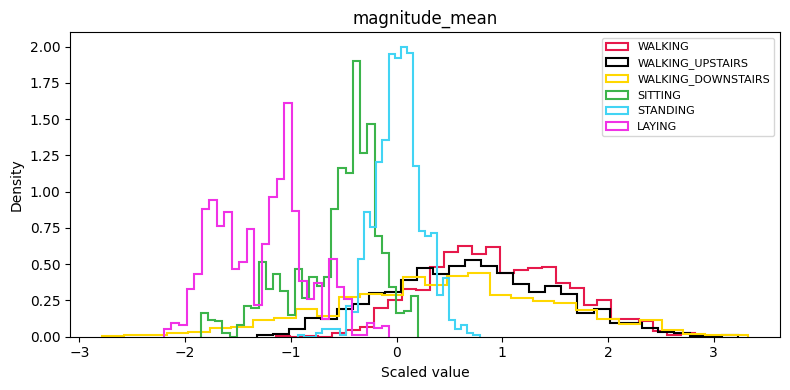

In [34]:
plot_feature_histogram('magnitude_mean', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

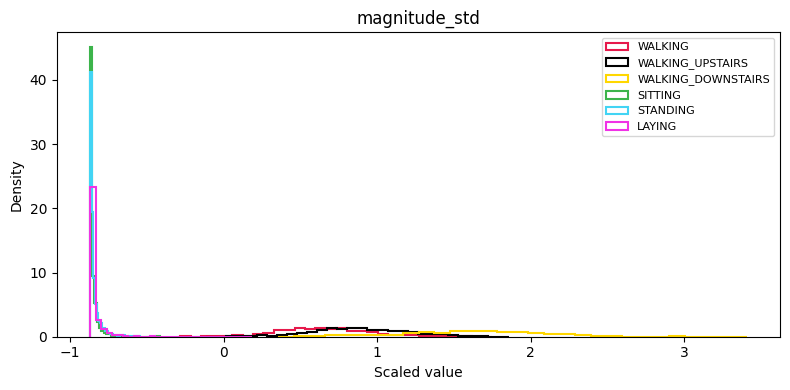

In [35]:
plot_feature_histogram('magnitude_std', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

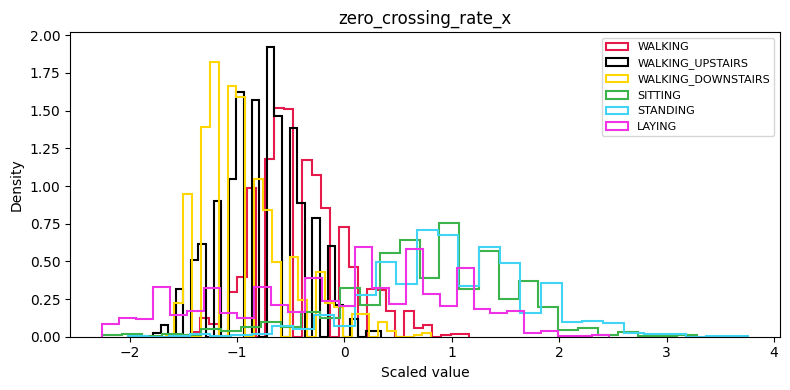

In [36]:
plot_feature_histogram('zero_crossing_rate_x', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

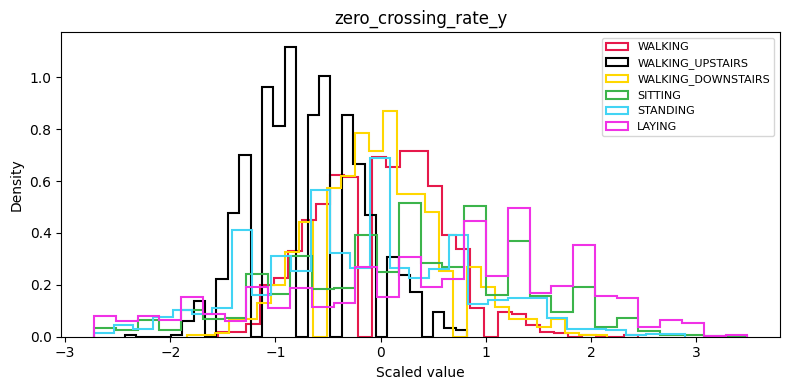

In [37]:
plot_feature_histogram('zero_crossing_rate_y', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

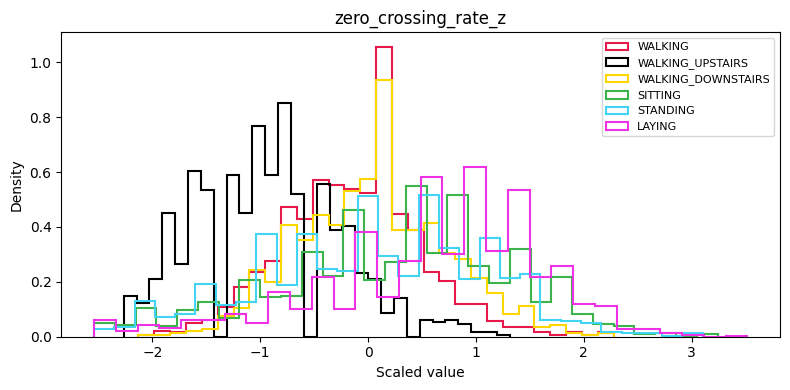

In [38]:
plot_feature_histogram('zero_crossing_rate_z', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

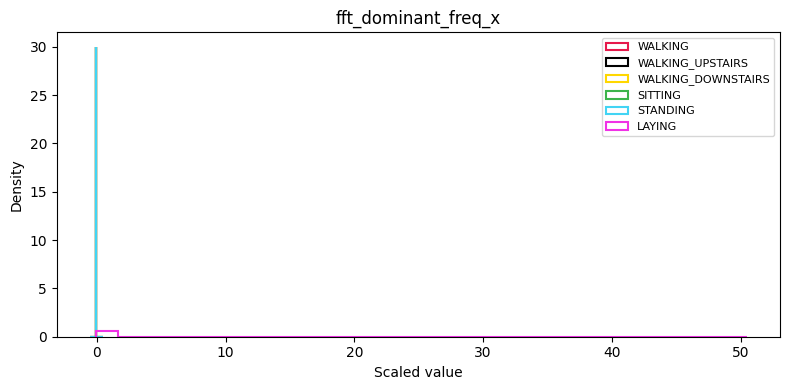

In [39]:
plot_feature_histogram('fft_dominant_freq_x', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

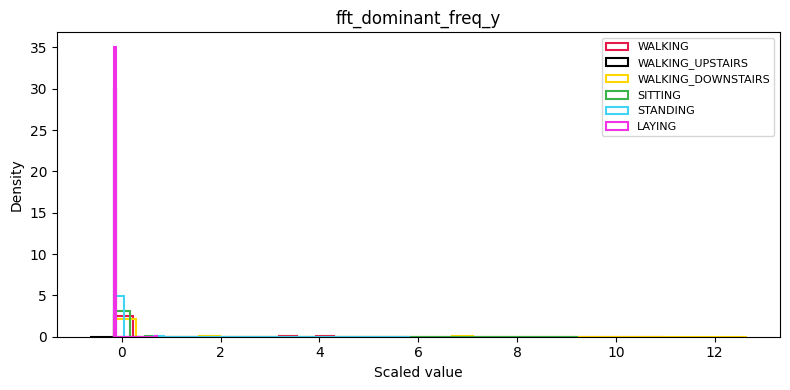

In [40]:
plot_feature_histogram('fft_dominant_freq_y', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

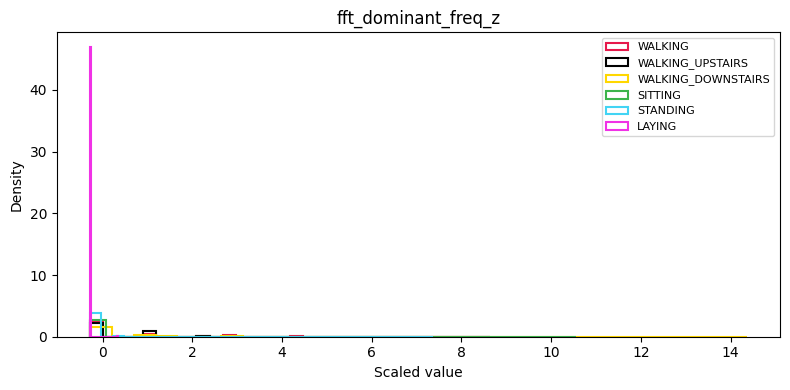

In [41]:
plot_feature_histogram('fft_dominant_freq_z', feature_names, X_train_scaled, y_train, ACTIVITY_LABELS)

In [42]:
def print_feature_stats(feature_name, feature_names, X_scaled, y, activity_labels):
    feat_idx = feature_names.index(feature_name)
    print(f"\nFeature: {feature_name}")
    print(f"{'Activity':<25} {'Mean':>8} {'Std':>8}")
    print("-" * 45)
    for label_id in sorted(activity_labels.keys()):
        mask = (y == label_id)
        mean = X_scaled[mask, feat_idx].mean()
        std = X_scaled[mask, feat_idx].std()
        print(f"{activity_labels[label_id]:<25} {mean:>8.3f} {std:>8.3f}")

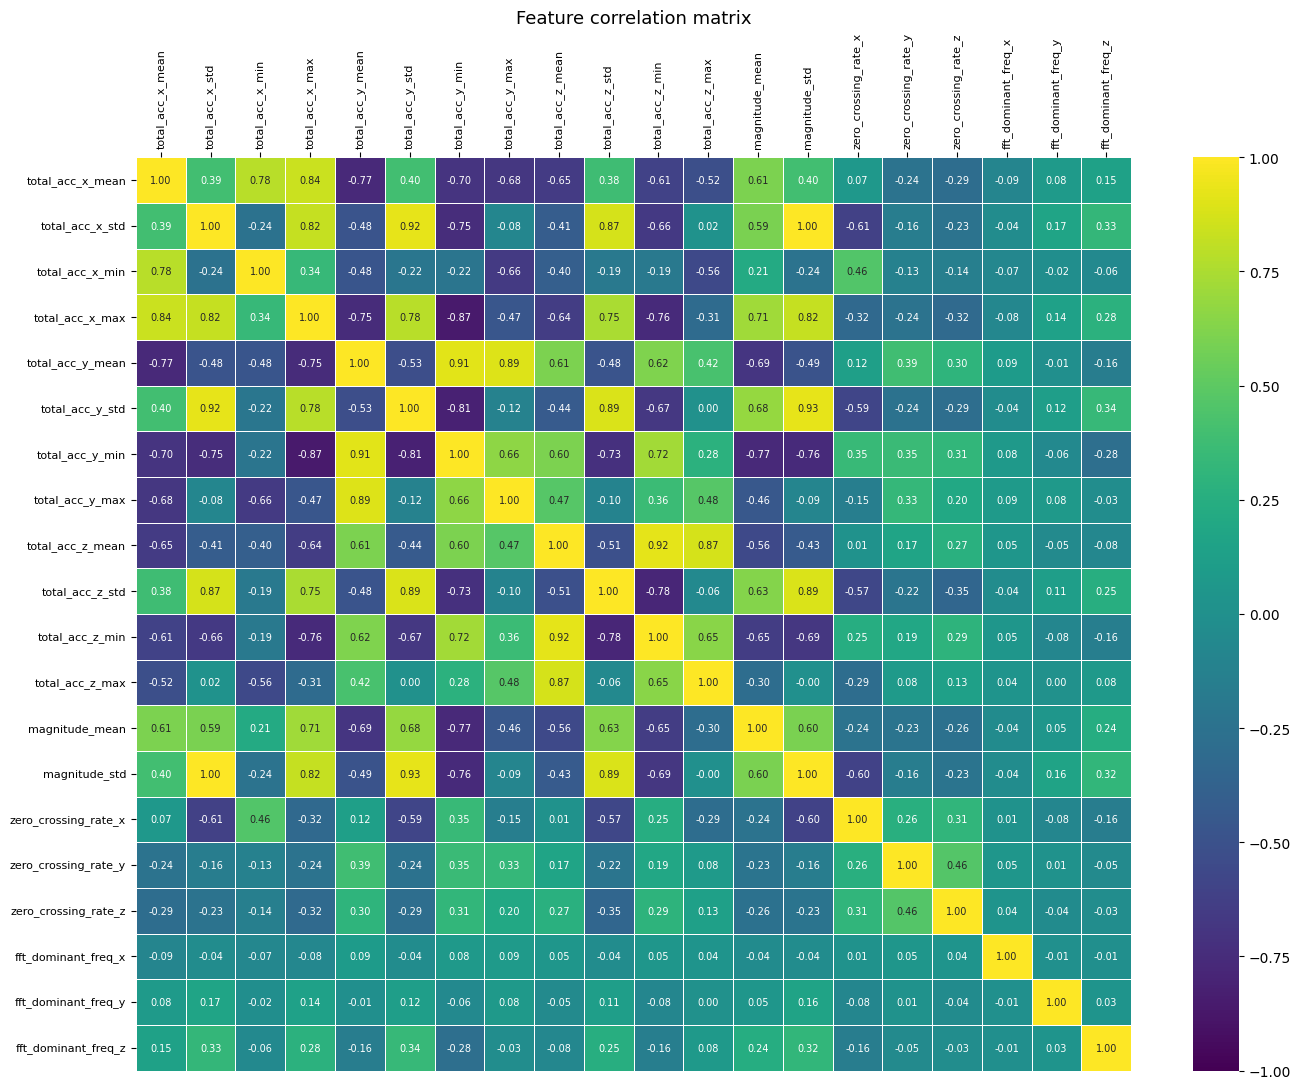





Highly correlated pairs (|correlation| > 0.85):

  total_acc_x_std  total_acc_y_std  r = 0.92
  total_acc_x_std  total_acc_z_std  r = 0.87
  total_acc_x_std  magnitude_std  r = 1.00
  total_acc_x_max  total_acc_y_min  r = -0.87
  total_acc_y_mean  total_acc_y_min  r = 0.91
  total_acc_y_mean  total_acc_y_max  r = 0.89
  total_acc_y_std  total_acc_z_std  r = 0.89
  total_acc_y_std  magnitude_std  r = 0.93
  total_acc_z_mean  total_acc_z_min  r = 0.92
  total_acc_z_mean  total_acc_z_max  r = 0.87
  total_acc_z_std  magnitude_std  r = 0.89


In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
corr_matrix = df_train_scaled.corr()

fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    corr_matrix,
    annot=True, # show the number inside each cell
    fmt='.2f', # round to 2 decimal places
    cmap='viridis',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    ax=ax,
    annot_kws={'size': 7}
)

ax.set_title('Feature correlation matrix', fontsize=13)
ax.xaxis.tick_top()
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# Print highly correlated pairs
print("\n\n\n\nHighly correlated pairs (|correlation| > 0.85):\n")
for i in range(len(feature_names)):
    for j in range(i+1, len(feature_names)):
        val = abs(corr_matrix.iloc[i, j])
        if val > 0.85:
            print(f"  {feature_names[i]}  {feature_names[j]}  r = {corr_matrix.iloc[i,j]:.2f}")

## Sub-question Q1.3


**Which features differentiate between classes and which don't ?**

The strongest differentiating features are total_acc_x_mean and total_acc_y_mean where LAYING separates clearly from all other classes and the std features (total_acc_x/y/z_std, magnitude_std) which cleanly split static activities (SITTING, STANDING, LAYING) from dynamic ones (WALKING variants). Features like total_acc_x_min, total_acc_x_max and magnitude_mean provide moderate separation. On the other hand fft_dominant_freq_x/y/z and zero_crossing_rate_y/z show almost complete overlap across all 6 classes and provide no meaningful separation

**If many features are correlated with each other, which classification algorithms will be affected the most and why ?**

The correlation matrix revealed 11 pairs with |r| > 0.85. Notably
total_acc_x_std and magnitude_std have r = 1.00 meaning they are
essentially identical features. The group total_acc_x_std, total_acc_y_std, total_acc_z_std, magnitude_std forms a highly correlated cluster (r = 0.87–1.00). Additionally total_acc_z_mean is strongly correlated with both total_acc_z_min (r = 0.92) and total_acc_z_max (r = 0.87)

The most affected classifiers are:

- Naive Bayes: this is the most affected algorithm because it assumes all features are completely independent. With r = 1.00 between total_acc_x_std and magnitude_std this assumption is severely violated. The model counts the same information twice which distorts the probability calculations and leads to overconfident wrong predictions

- Logistic Regression: correlated features cause multicollinearity meaning
the model cannot reliably estimate the weight of each feature. For example
total_acc_x_std and magnitude_std have r = 1.00 meaning they carry exactly
the same information so the model cannot decide how to split the weight
between them

- k-NN: correlated features inflate the importance of certain directions in the feature space. Since total_acc_x_std, total_acc_y_std, total_acc_z_std and magnitude_std are all highly correlated the distance calculation is dominated by this group of features giving them 4x more weight than intended


The least affected classifiers are:

- Decision Tree: because at each split it selects only one feature at a time so it naturally ignores redundant correlated ones

- SVM: especially with the rbf kernel it is more robust to correlated features because it operates on the geometry of the data rather than on individual feature weights



### 1.4 Dimensionality Reduction and Visualization

In [44]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

colors = ['#e6194b', '#000000', '#FFD700', '#3cb44b', '#42d4f4', '#f032e6']

def plot_2d(X_2d, y, title, activity_labels, colors):
    fig, ax = plt.subplots(figsize=(9, 6))
    for label_idx, label_id in enumerate(sorted(activity_labels.keys())):
        mask = (y == label_id)
        ax.scatter(
            X_2d[mask, 0], X_2d[mask, 1],
            c=colors[label_idx],
            label=activity_labels[label_id],
            s=10, alpha=0.6
        )
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

PC1 explained variance: 0.438
PC2 explained variance: 0.184
Total explained variance: 0.622


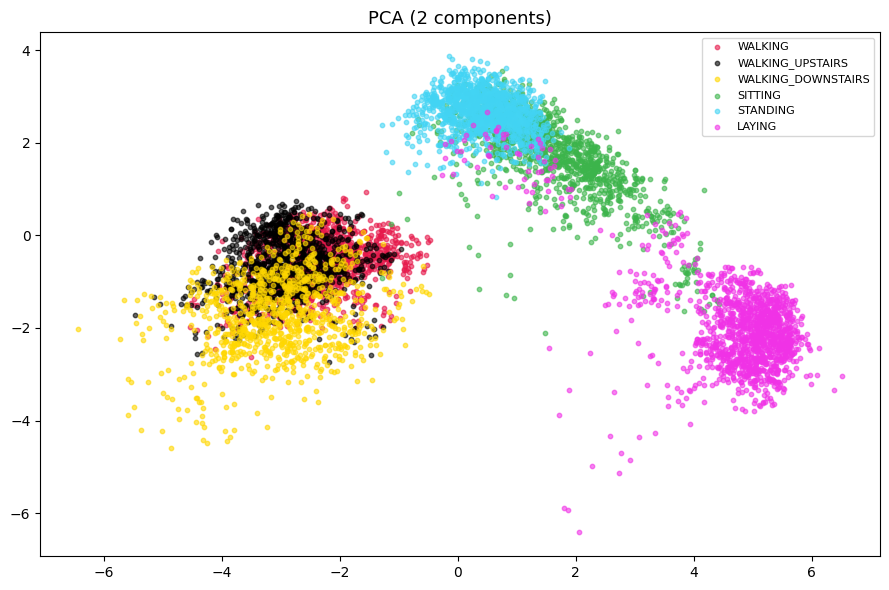

In [45]:
pca_2d = PCA(n_components=2, random_state=42)

X_pca = pca_2d.fit_transform(X_train_scaled)

print(f"PC1 explained variance: {pca_2d.explained_variance_ratio_[0]:.3f}")
print(f"PC2 explained variance: {pca_2d.explained_variance_ratio_[1]:.3f}")
print(f"Total explained variance: {pca_2d.explained_variance_ratio_.sum():.3f}")

plot_2d(X_pca, y_train, 'PCA (2 components)', ACTIVITY_LABELS, colors)

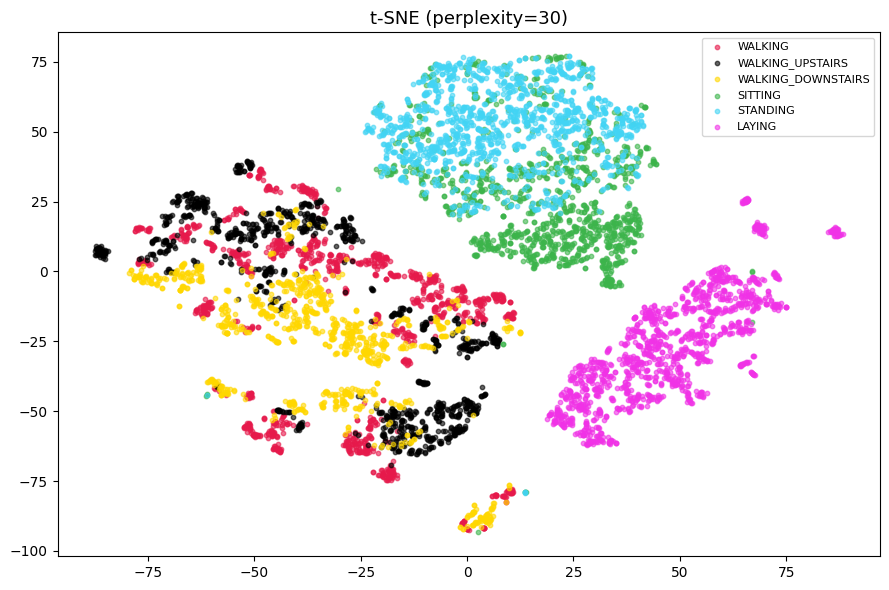

In [46]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    init='pca',
    learning_rate='auto',
    perplexity=30
)

X_tsne = tsne.fit_transform(X_train_scaled)

plot_2d(X_tsne, y_train, 't-SNE (perplexity=30)', ACTIVITY_LABELS, colors)

In [47]:
!pip install umap-learn -q
import umap.umap_ as umap_

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


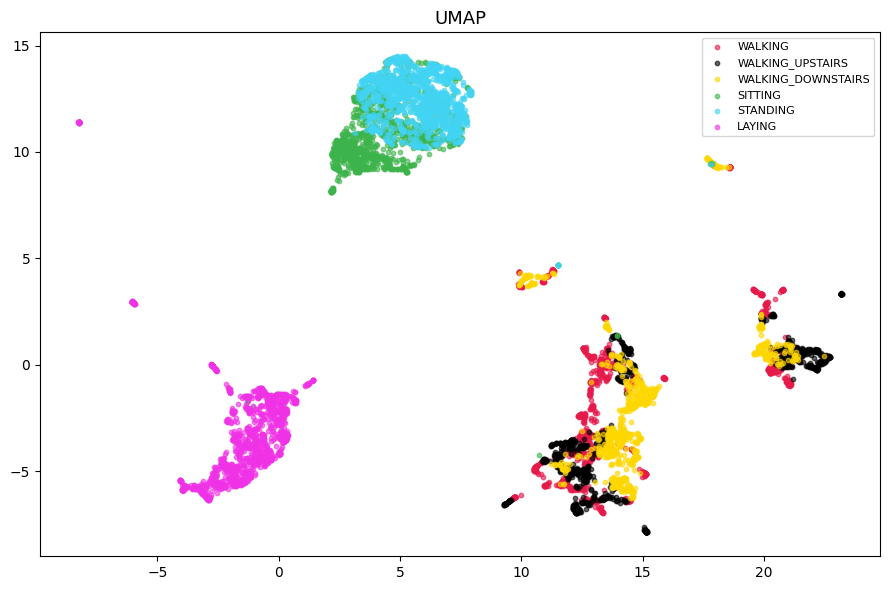

In [48]:
reducer = umap_.UMAP(n_components=2, random_state=42)

X_umap = reducer.fit_transform(X_train_scaled)

plot_2d(X_umap, y_train, 'UMAP', ACTIVITY_LABELS, colors)

## Sub-question Q1.4

PCA captured 43.8% of the variance in PC1 and 18.4% in PC2 for a total
of 62.2% meaning 37.8% of the information is lost in this 2D projection.
LAYING is mostly isolated but SITTING overlaps with STANDING and the three walking activities (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) are completely mixed together

<br>

t-SNE shows much better separation than PCA. LAYING and STANDING are not
so overlapping compared to the PCA. The LAYING is a perfectly isolated cluster. The three walking activities are still heavily overlapping but t-SNE reveals internal sub clusters within the walking group that PCA could not show. This improvement is because t-SNE is non-linear and better preserves the local structure of the data

<br>

UMAP shows the best separation of all three methods. STANDING and SITTING are not so overlapping compared to t-SNE and LAYING forms a more compact and concentrated cluster in UMAP compared to t-SNE. The three walking activities remain mixed but UMAP reveals more internal sub clusters than both PCA and t-SNE

<br>

All three methods agree that the walking activities are the hardest to separate. The fact that t-SNE and UMAP that are both non-linear methods are needed to reveal the cluster structure confirms that the data is not linearly separable

SVM with rbf kernel is expected to perform best since the walking
activities overlap in a non-linear way and the rbf kernel can handle
a non-linear decision. k-NN should also perform well since the clusters are compact and nearby samples tend to share the same label. Decision Tree may struggle with the walking overlap since it creates axis aligned boundaries that cannot capture curved separations well. Logistic Regression is expected to perform worst on the walking activities since it is a linear model and the walking classes are not linearly separable. Naive Bayes may also struggle since the features are correlated (as seen in Q1.3) and its independence assumption is violated


## 2 Training and Comparison of Algorithms

In [49]:
import numpy as np
import random


np.random.seed(42)
random.seed(42)

In [50]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

In [51]:
from sklearn.metrics import (accuracy_score, f1_score)

# Section: DummyClassifier Baseline part

print("=" * 40)
print("Dummy Classifier Baseline")
print("=" * 40)

dummy = DummyClassifier(strategy='most_frequent', random_state=42)
dummy.fit(X_train_scaled, y_train)

dummy_val_acc = accuracy_score(y_val, dummy.predict(X_val_scaled))
dummy_val_f1 = f1_score(y_val, dummy.predict(X_val_scaled), average='macro')
dummy_test_acc = accuracy_score(y_test, dummy.predict(X_test_scaled))
dummy_test_f1  = f1_score(y_test, dummy.predict(X_test_scaled), average='macro')

print(f"Val Accuracy : {dummy_val_acc  * 100:.2f}%")
print(f"Val F1 macro : {dummy_val_f1   * 100:.2f}%")
print(f"Test Accuracy : {dummy_test_acc * 100:.2f}%")

Dummy Classifier Baseline
Val Accuracy : 18.90%
Val F1 macro : 5.30%
Test Accuracy : 18.83%


In [52]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier


# Section: k-NN part


print("=" * 60)
print("k-NN Part using 5-fold cross-validation")
print("=" * 60)


knn_param_grid = {
    "n_neighbors" : [1, 3, 5, 11, 21],
    'metric' : ['euclidean', 'cosine']
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

knn_grid.fit(X_train_scaled, y_train)

best_knn = knn_grid.best_estimator_

print()
print(f"Best params : {knn_grid.best_params_}")
print(f"Best 5-fold cross-validation F1: {knn_grid.best_score_ * 100:.2f}%")

results['k-NN'] = {
    'best_params' : knn_grid.best_params_,
    'model' : best_knn,
    'val_acc' : accuracy_score(y_val, best_knn.predict(X_val_scaled)),
    'val_f1' : f1_score(y_val, best_knn.predict(X_val_scaled), average='macro'),
    'test_acc' : accuracy_score(y_test, best_knn.predict(X_test_scaled)),
    'test_f1' : f1_score(y_test, best_knn.predict(X_test_scaled), average='macro'),
}

print()
print(f"Val Accuracy : {results['k-NN']['val_acc'] * 100:.2f}%")
print(f"Val F1 Macro : {results['k-NN']['val_f1'] * 100:.2f}%")
print(f"Test Accuracy : {results['k-NN']['test_acc'] * 100:.2f}%")
print(f"Test F1 Macro : {results['k-NN']['test_f1'] * 100:.2f}%")

k-NN Part using 5-fold cross-validation

Best params : {'metric': 'euclidean', 'n_neighbors': 3}
Best 5-fold cross-validation F1: 92.55%

Val Accuracy : 92.23%
Val F1 Macro : 92.26%
Test Accuracy : 91.84%
Test F1 Macro : 91.91%


In [53]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score


# Section: Naive Bayes part


print("=" * 60)
print("Naive Bayes Part using 5-fold cross-validation")
print("=" * 60)


best_nb = GaussianNB()

nb_cv_f1 = cross_val_score(
    best_nb,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
).mean()

best_nb.fit(X_train_scaled, y_train)

print()
print(f"Best params : GaussianNB")
print(f"Best 5-fold cross-validation F1: {nb_cv_f1 * 100:.2f}%")

results['Naive Bayes'] = {
    'best_params' : 'GaussianNB',
    'model' : best_nb,
    'val_acc' : accuracy_score(y_val, best_nb.predict(X_val_scaled)),
    'val_f1' : f1_score(y_val, best_nb.predict(X_val_scaled), average='macro'),
    'test_acc' : accuracy_score(y_test, best_nb.predict(X_test_scaled)),
    'test_f1' : f1_score(y_test, best_nb.predict(X_test_scaled), average='macro'),
}

print()
print(f"Val Accuracy : {results['Naive Bayes']['val_acc'] * 100:.2f}%")
print(f"Val F1 Macro : {results['Naive Bayes']['val_f1'] * 100:.2f}%")
print(f"Test Accuracy : {results['Naive Bayes']['test_acc'] * 100:.2f}%")
print(f"Test F1 Macro : {results['Naive Bayes']['test_f1'] * 100:.2f}%")


Naive Bayes Part using 5-fold cross-validation

Best params : GaussianNB
Best 5-fold cross-validation F1: 66.39%

Val Accuracy : 69.90%
Val F1 Macro : 65.18%
Test Accuracy : 69.77%
Test F1 Macro : 65.10%


In [54]:
from sklearn.linear_model import LogisticRegression


# Section: Logistic Regression part


print("=" * 60)
print("Logistic Regression Part using 5-fold cross-validation")
print("=" * 60)


lr_param_grid = [
    {
        'C' : [0.01, 0.1, 1, 10, 100],
        'penalty' : ['l1'],
        'solver' : ['saga', 'liblinear'],
        'max_iter' : [500]
    },
    {
        'C' : [0.01, 0.1, 1, 10, 100],
        'penalty' : ['l2'],
        'solver' : ['saga'],
        'max_iter' : [500]
    }
]

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    lr_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

lr_grid.fit(X_train_scaled, y_train)

best_lr = lr_grid.best_estimator_

print()
print(f"Best params : {lr_grid.best_params_}")
print(f"Best 5-fold cross-validation F1: {lr_grid.best_score_ * 100:.2f}%")

results['Logistic Regression'] = {
    'best_params' : lr_grid.best_params_,
    'model' : best_lr,
    'val_acc' : accuracy_score(y_val, best_lr.predict(X_val_scaled)),
    'val_f1' : f1_score(y_val, best_lr.predict(X_val_scaled), average='macro'),
    'test_acc' : accuracy_score(y_test, best_lr.predict(X_test_scaled)),
    'test_f1' : f1_score(y_test, best_lr.predict(X_test_scaled), average='macro'),
}

print()
print(f"Val Accuracy : {results['Logistic Regression']['val_acc'] * 100:.2f}%")
print(f"Val F1 Macro : {results['Logistic Regression']['val_f1'] * 100:.2f}%")
print(f"Test Accuracy : {results['Logistic Regression']['test_acc'] * 100:.2f}%")
print(f"Test F1 Macro : {results['Logistic Regression']['test_f1'] * 100:.2f}%")

Logistic Regression Part using 5-fold cross-validation

Best params : {'C': 10, 'max_iter': 500, 'penalty': 'l1', 'solver': 'saga'}
Best 5-fold cross-validation F1: 89.75%

Val Accuracy : 89.19%
Val F1 Macro : 89.01%
Test Accuracy : 88.80%
Test F1 Macro : 88.69%


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [55]:
from sklearn.svm import SVC


# Section: SVM part


print("=" * 60)
print("SVM Part using 5-fold cross-validation")
print("=" * 60)

svm_param_grid = {
    'kernel' : ['linear', 'rbf', 'poly'],
    'C' : [0.1, 1, 10, 100]
}

svm_grid = GridSearchCV(
    SVC(random_state=42),
    svm_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

best_svm = svm_grid.best_estimator_

print()
print(f"Best params : {svm_grid.best_params_}")
print(f"Best 5-fold cross-validation F1: {svm_grid.best_score_ * 100:.2f}%")

results['SVM'] = {
    'best_params' : svm_grid.best_params_,
    'model' : best_svm,
    'val_acc' : accuracy_score(y_val, best_svm.predict(X_val_scaled)),
    'val_f1' : f1_score(y_val, best_svm.predict(X_val_scaled), average='macro'),
    'test_acc' : accuracy_score(y_test, best_svm.predict(X_test_scaled)),
    'test_f1' : f1_score(y_test, best_svm.predict(X_test_scaled), average='macro'),
}

print()
print(f"Val Accuracy : {results['SVM']['val_acc'] * 100:.2f}%")
print(f"Val F1 Macro : {results['SVM']['val_f1'] * 100:.2f}%")
print(f"Test Accuracy : {results['SVM']['test_acc'] * 100:.2f}%")
print(f"Test F1 Macro : {results['SVM']['test_f1'] * 100:.2f}%")


SVM Part using 5-fold cross-validation

Best params : {'C': 100, 'kernel': 'rbf'}
Best 5-fold cross-validation F1: 93.97%

Val Accuracy : 94.69%
Val F1 Macro : 94.87%
Test Accuracy : 93.66%
Test F1 Macro : 93.80%


In [56]:
from sklearn.tree import DecisionTreeClassifier


# Section: Decision Tree Part


print("=" * 60)
print("Decision Tree Part using 5-fold cross-validation")
print("=" * 60)

dt_param_grid = {
    'max_depth' : [3, 5, 10, None],
    'min_samples_leaf' : [1, 5, 10]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

dt_grid.fit(X_train_scaled, y_train)

best_dt = dt_grid.best_estimator_

print()
print(f"Best params : {dt_grid.best_params_}")
print(f"Best 5-fold cross-validation F1: {dt_grid.best_score_ * 100:.2f}%")

results['Decision Tree'] = {
    'best_params' : dt_grid.best_params_,
    'model' : best_dt,
    'val_acc' : accuracy_score(y_val, best_dt.predict(X_val_scaled)),
    'val_f1' : f1_score(y_val, best_dt.predict(X_val_scaled), average='macro'),
    'test_acc' : accuracy_score(y_test, best_dt.predict(X_test_scaled)),
    'test_f1' : f1_score(y_test, best_dt.predict(X_test_scaled), average='macro'),
}

print()
print(f"Val Accuracy : {results['Decision Tree']['val_acc'] * 100:.2f}%")
print(f"Val F1 Macro : {results['Decision Tree']['val_f1'] * 100:.2f}%")
print(f"Test Accuracy : {results['Decision Tree']['test_acc'] * 100:.2f}%")
print(f"Test F1 Macro : {results['Decision Tree']['test_f1'] * 100:.2f}%")

Decision Tree Part using 5-fold cross-validation

Best params : {'max_depth': None, 'min_samples_leaf': 1}
Best 5-fold cross-validation F1: 91.47%

Val Accuracy : 92.43%
Val F1 Macro : 92.06%
Test Accuracy : 92.69%
Test F1 Macro : 92.45%


In [57]:
# from sklearn.tree import export_text
# rules = export_text(best_dt, feature_names=feature_names)
# print(rules)

## Sub-question Q2.1 Summary Table

In [58]:
rows = []

# Add Dummy Baseline
rows.append({
    'Algorithm' : 'Dummy Baseline',
    'Best Params' : 'most_frequent',
    'Val Acc' : f"{dummy_val_acc * 100:.2f}%",
    'Val F1' : f"{dummy_val_f1 * 100:.2f}%",
    'Test Acc' : f"{dummy_test_acc * 100:.2f}%",
    'Test F1' : f"{dummy_test_f1 * 100:.2f}%",
})

# Add all trained models
for name, res in results.items():
    rows.append({
        'Algorithm' : name,
        'Best Params' : str(res['best_params']),
        'Val Acc' : f"{res['val_acc'] * 100:.2f}%",
        'Val F1' : f"{res['val_f1'] * 100:.2f}%",
        'Test Acc' : f"{res['test_acc'] * 100:.2f}%",
        'Test F1' : f"{res['test_f1']  * 100:.2f}%",
    })

summary_df = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', None)
display(summary_df.style.set_caption("Q2.1 Summary Table"))

,Algorithm,Best Params,Val Acc,Val F1,Test Acc,Test F1
0,Dummy Baseline,most_frequent,18.90%,5.30%,18.83%,5.28%
1,k-NN,"{'metric': 'euclidean', 'n_neighbors': 3}",92.23%,92.26%,91.84%,91.91%
2,Naive Bayes,GaussianNB,69.90%,65.18%,69.77%,65.10%
3,Logistic Regression,"{'C': 10, 'max_iter': 500, 'penalty': 'l1', 'solver': 'saga'}",89.19%,89.01%,88.80%,88.69%
4,SVM,"{'C': 100, 'kernel': 'rbf'}",94.69%,94.87%,93.66%,93.80%
5,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 1}",92.43%,92.06%,92.69%,92.45%


## Sub-question Q2.2 Confusion Matrix

Best Algorithm: SVM




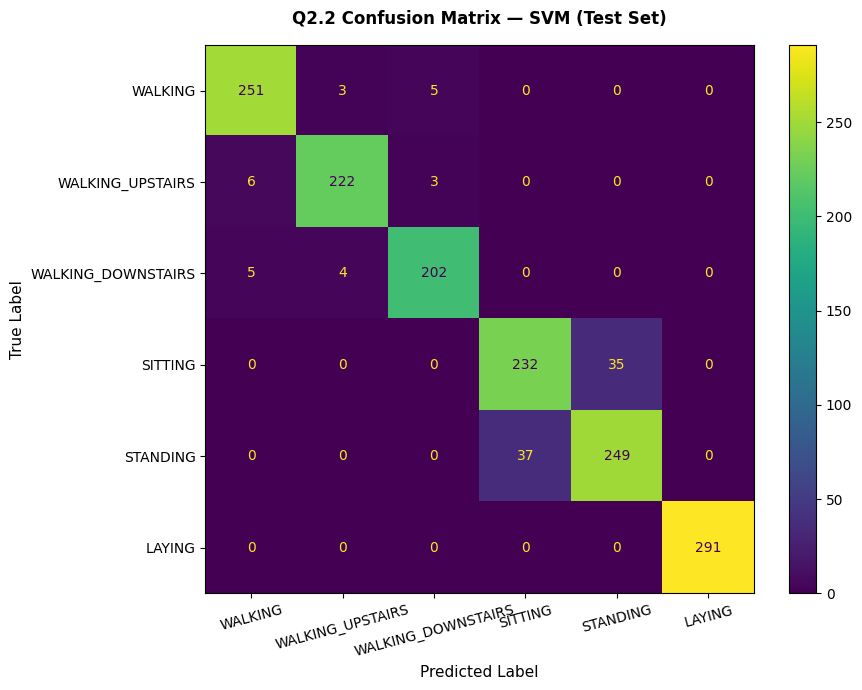



Confusion Matrix (raw counts):
Labels: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
[[251   3   5   0   0   0]
 [  6 222   3   0   0   0]
 [  5   4 202   0   0   0]
 [  0   0   0 232  35   0]
 [  0   0   0  37 249   0]
 [  0   0   0   0   0 291]]


In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Find best model based on Test macro F1 score
best_name = max(results, key=lambda x: results[x]['test_f1'])
best_model = results[best_name]['model']

print(f"Best Algorithm: {best_name}\n\n")

# Predict on test set
y_pred = best_model.predict(X_test_scaled)

# Get activity names in order 1-6
labels = [ACTIVITY_LABELS[i] for i in sorted(ACTIVITY_LABELS.keys())]

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=sorted(ACTIVITY_LABELS.keys()))

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap='viridis', colorbar=True)

ax.set_title(f"Q2.2 Confusion Matrix — {best_name} (Test Set)",
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\n")
print("Confusion Matrix (raw counts):")
print(f"Labels: {labels}")
print(cm)

The best algorithm is SVM which is consistent with the prediction made
in Q1.4 where we expected SVM with rbf kernel to perform best since the
walking activities overlap in a non-linear way and the rbf kernel can
handle a non-linear decision. The confusion matrix reveals two main sources of confusion:

SITTING Activity with STANDING Activity is the biggest problem with 35 SITTING predicted as STANDING and 37 STANDING predicted as SITTING (72 total errors). This is fully explained by Q1.3 and Q1.4: in Q1.3 features like total_acc_y_min, total_acc_x_max and total_acc_y_mean all show SITTING and STANDING overlapping in the middle range since both are static activities with minimal movement. In Q1.4 all three visualizations confirm this since in PCA SITTING overlaps with STANDING, in t-SNE they are less overlapping but still not fully separated and even in UMAP which shows the best separation of all three methods SITTING and STANDING are still not completely separated confirming that our 20 features cannot find a clear boundary between them

<br>

Walking activities (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) show
minor confusion among themselves (at most 6 errors between any pair)
despite both the histograms in Q1.3 and all three visualizations in Q1.4
showing them as heavily overlapping. This is because histograms look at
one feature at a time and visualizations reduce 20 dimensions down to 2
both losing information in the process. In the full 20 dimensional feature
space SVM with rbf kernel can find complex decision boundaries that are
not visible when looking at individual features or 2D projections which
explains why the walking activities are actually well separated in
practice despite appearing mixed in both the histograms and visualizations

<br>

LAYING is classified perfectly (291/291) which is fully consistent with
Q1.3 and Q1.4. In Q1.3 features like total_acc_x_mean, total_acc_y_mean
and total_acc_y_min all show LAYING as a completely isolated cluster far
from all other classes. In Q1.4 in PCA LAYING is mostly isolated, in t-SNE it forms a perfectly isolated cluster and in UMAP it becomes even more compact and concentrated compared to t-SNE making LAYING the easiest class to classify correctly


## Sub-question Q2.3

In [60]:
# Get predictions from all models
all_predictions = {}
for name, res in results.items():
                                         # Predict on test set
    all_predictions[name] = res['model'].predict(X_test_scaled)

error_indices_per_model = {}
# Find indices where algorithms are wrong
for name, preds in all_predictions.items():

    if name == 'Dummy Baseline':
        continue

    error_indices_per_model[name] = {i for i, (p, t) in enumerate(zip(preds, y_test)) if p != t}

# Identify common failures across all models
common_errors = set(range(len(y_test)))
for errors in error_indices_per_model.values():

    # We create a new set by checking if each index 'i' is actually a mistake
    common_errors = {i for i in common_errors if i in errors}

common_errors = sorted(list(common_errors))

print(f"Samples misclassified by ALL algorithms: {len(common_errors)}\n\n")

models_to_check = ['k-NN', 'Naive Bayes', 'Logistic Regression', 'SVM', 'Decision Tree']
header = f"{'Index':<8} {'True Label':<25} {'k-NN':<20} {'Naive Bayes':<20} {'Logistic Reg':<20} {'SVM':<20} {'Decision Tree':<20}"
print(header)
print("-" * len(header))

for idx in common_errors:
    true_label = ACTIVITY_LABELS[y_test[idx]]
    preds = {name: ACTIVITY_LABELS[all_predictions[name][idx]] for name in models_to_check}

    row = f"{idx:<8} {true_label:<25} {preds['k-NN']:<20} {preds['Naive Bayes']:<20} {preds['Logistic Regression']:<20} {preds['SVM']:<20} {preds['Decision Tree']:<20}"
    print(row)

Samples misclassified by ALL algorithms: 14


Index    True Label                k-NN                 Naive Bayes          Logistic Reg         SVM                  Decision Tree       
-------------------------------------------------------------------------------------------------------------------------------------------
90       SITTING                   STANDING             STANDING             STANDING             STANDING             STANDING            
150      SITTING                   STANDING             STANDING             STANDING             STANDING             STANDING            
167      SITTING                   STANDING             STANDING             STANDING             STANDING             STANDING            
371      WALKING                   WALKING_DOWNSTAIRS   WALKING_UPSTAIRS     WALKING_DOWNSTAIRS   WALKING_DOWNSTAIRS   WALKING_DOWNSTAIRS  
441      STANDING                  SITTING              SITTING              SITTING              SITTING         

Group 1: SITTING <=> STANDING confusion (10 out of 14 total errors)

- 6 samples (index 90, 150, 167, 591, 776, 1131) have true label **SITTING** but every algorithm predicts them **STANDING**
- 4 samples (index 441, 820, 1006, 1513) have true label **STANDING** but every algorithm predicts them **SITTING**

The cause is data ambiguity. As shown in Q1.3, both SITTING and STANDING are static activities with minimal movement. The std features (total_acc_x_std, total_acc_y_std, total_acc_z_std, magnitude_std) show both classes clustered in the same region with no meaningful separation between them and features like total_acc_x_max and total_acc_y_min show heavy overlap between SITTING and STANDING in the middle range. This is further confirmed in Q1.4 where even UMAP could not fully separate them.
Since all 5 algorithms agree on the wrong answer, this is a strong signal that the data itself is ambiguous, not that the features are bad.

<br>

**Group 2: Walking activity confusion (4 out of 14 total errors)**

- 2 samples (index 371, 858) have true label **WALKING** but most algorithms predict **WALKING_DOWNSTAIRS**
- 2 samples (index 573, 1182) have true label **WALKING_DOWNSTAIRS** but algorithms predict a mix of **WALKING** and **WALKING_UPSTAIRS**

All three walking activities (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) are dynamic activities with similar movement patterns. As noted in Q1.3, the std features and zero_crossing_rate_x only separate dynamic from static activities as a group but cannot distinguish between the three walking types individually. These 4 samples represent windows where the walking movement was similar enough to another walking style to fool every classifier.
<br><br>
**Conclusion:** The errors are caused by data ambiguity, not by poor features. The features correctly capture the overall movement patterns, but certain windows of SITTING/STANDING and different walking styles are genuinely indistinguishable regardless of the features used.

## Sub-question Q2.4


The best accuracy algorithm is not always the best choice. Based on our results, SVM achieved the best test accuracy (93.66%), F1 macro (93.80%) but there are three reasons why a simpler algorithm like Decision Tree accuracy (92.69%), F1 macro (92.45%) can be a better choice:
<br> <br>
**Performance:** The gap between SVM and Decision Tree is less than 1%.
In most applications this difference is not worth the extra complexity.
SVM is only worth it in critical applications such as medical or safety systems where every wrong prediction has serious consequences.
<br> <br>
**Interpretability:** Decision Tree can explain its decisions at each node i.e. produces explicit if-then rules that someone can read and verify, for example in our case to explain why a specific activity was classified as LAYING rather than SITTING, which is important when someone needs to understand why the model made a decision. SVM with rbf kernel offers no such explanation since its decision boundary is a non-linear combination of support vectors in a high dimensional space.
<br> <br>
**Computational cost:** SVM with rbf kernel is significantly slower to train and predict than Decision Tree. For a HAR (Human Activity Recognition) system that needs to retrain frequently as new activity data
is collected, or scale to many users, this training cost becomes significant. Additionally, if the system ever needs to run on device, which is the most common deployment scenario for activity recognition systems where limited battery and CPU make this cost matter, Decision Tree is far more suitable than SVM with rbf kernel for real time inference on low power hardware.
<br> <br>
So the answer to the manager is: use the best accuracy algorithm only when the performance gain is meaningful and the extra complexity is justified. In our case, Decision Tree is likely the better choice since it is within 1% of SVM, explains its decisions and runs efficiently on the mobile hardware where HAR systems are actually deployed.

## 3. Evaluation of Classifiers under Distribution Shift

In [61]:
print("Extracting features from personal data using the same pipeline as UCI HAR Dataset...")

# Step 1: Apply the EXACT same feature extraction function used on UCI HAR Dataset
X_own_features = extract_basic_features(X_own_raw)

# Verification 1: Shape check
print(f"X_own_features shape : {X_own_features.shape}")
print(f"X_train_features shape : {X_train_features.shape}")
print(f"Feature vector size matches UCI HAR Dataset : {X_own_features.shape[1] == X_train_features.shape[1]}")

# Verification 2: NaN or Inf
print(f"\nNaN values : {np.isnan(X_own_features).sum()}")
print(f"Inf values : {np.isinf(X_own_features).sum()}")

# Verification 3: values should be in a reasonable range
print(f"\nMin value : {X_own_features.min():.4f}")
print(f"Max value : {X_own_features.max():.4f}")
print(f"Mean value : {X_own_features.mean():.4f}")

Extracting features from personal data using the same pipeline as UCI HAR Dataset...
X_own_features shape : (458, 20)
X_train_features shape : (7209, 20)
Feature vector size matches UCI HAR Dataset : True

NaN values : 0
Inf values : 0

Min value : -1.4603
Max value : 8.5938
Mean value : 0.2052


In [62]:
# Step 2: Apply the SAME scaler fitted on the UCI HAR Dataset training set — NO new fit
X_own_scaled = scaler.transform(X_own_features)


print(f"X_own_scaled shape : {X_own_scaled.shape}")
print(f"NaN after scaling : {np.isnan(X_own_scaled).sum()}")
print(f"Inf after scaling : {np.isinf(X_own_scaled).sum()}")

X_own_scaled shape : (458, 20)
NaN after scaling : 0
Inf after scaling : 0


In [63]:
# Summary of what we have
print("\nPersonal data ready for evaluation:")
print(f"{'Activity':<25} {'Windows':>10}")
print("-" * 37)
for label_id, label_name in ACTIVITY_LABELS.items():
    count = np.sum(y_own_raw == label_id)
    if count > 0:
        print(f"{label_name:<25} {count:>10}")
print(f"\nTotal windows: {len(y_own_raw)}")


Personal data ready for evaluation:
Activity                     Windows
-------------------------------------
WALKING                          148
WALKING_UPSTAIRS                 140
STANDING                          83
LAYING                            87

Total windows: 458


## Sub-question Q3.0

During feature extraction from the personal data one problem was
encountered: a units mismatch between the UCI HAR dataset and our
personal data. The shape mismatch however was anticipated and solved in
advance inside the process_all_collected_data() function.

The personal recordings only contain 3 axes (total_acc_x, total_acc_y,
total_acc_z) while the UCI HAR format requires shape (128, 9). If the
personal data windows were stored as (128, 3) the extract_basic_features()
function would crash because it reads columns 6, 7, 8 which would not
exist in a (128, 3) array.

To avoid this, each window was initialized as np.zeros((128, 9)) and
the 3 acceleration axes were placed in columns 6, 7, 8 to match the
UCI HAR format exactly. The remaining columns (0-5) were left as zeros.
This is consistent with how the feature extraction was set up since
extract_basic_features() only reads columns 6, 7, 8 so the zeros in
the other columns have no effect on the output.

As a result extract_basic_features() produced a feature vector of shape
(458, 20) which matches the UCI HAR feature vector shape (7209, 20) perfectly, with no NaN or Inf values.

The units mismatch was discovered when running Section 3.1 where the
model predicted every single sample as LAYING regardless of the true
activity. The accuracy was only 19% which is exactly 87/458 i.e. the
proportion of LAYING samples in the personal data, meaning the model
learned nothing useful.

After investigating the results I found the root cause of the problem:
a units mismatch between the UCI HAR dataset and our dataset.
```
Specifically:

UCI HAR dataset total_acc value ranges:
  total_acc_x -> min: -0.4666  max: 2.1976
  total_acc_y -> min: -1.5882  max: 1.2173
  total_acc_z -> min: -1.6396  max: 1.2814

Our own dataset total_acc value ranges (before conversion):
  total_acc_x -> min: -4.7125  max: 15.7172
  total_acc_y -> min: -14.3206  max: 7.3736
  total_acc_z -> min: -8.4130  max: 21.2388
```
The scales are completely different. Reading the README.txt of the UCI
HAR dataset, it explicitly states:
"The units used for the accelerations (total and body) are g's
(gravity of earth -> 9.80665 m/seg2)"

While our Phyphox app records in m/s^2 as shown in the CSV column names:
  Acceleration x (m/s^2)
  Acceleration y (m/s^2)
  Acceleration z (m/s^2)

Since 1g = 9.80665 m/s^2, dividing our values by 9.80665 converts them
from m/s^2 to g units i.e. the same scale as UCI HAR. After this
conversion the accuracy improved from 19% to 47% confirming that the
units mismatch was the primary cause.


## 3.1 First evaluation on personal data

In [64]:
# print(open('/content/UCI_HAR/UCI HAR Dataset/README.txt', encoding='latin-1').read())

In [65]:
from sklearn.metrics import classification_report

y_own_pred = best_model.predict(X_own_scaled)

own_acc = accuracy_score(y_own_raw, y_own_pred)
own_f1 = f1_score(y_own_raw, y_own_pred, average='macro')

print(f"UCI HAR Test Set : Accuracy: {results[best_name]['test_acc']*100:.2f}%  |  F1 macro: {results[best_name]['test_f1']*100:.2f}%")
print(f"Personal Data :    Accuracy: {own_acc*100:.2f}%  |  F1 macro: {own_f1*100:.2f}%")
print(f"\nAccuracy drop : {(results[best_name]['test_acc'] - own_acc)*100:.2f}%")
print(f"F1 drop : {(results[best_name]['test_f1']  - own_f1)*100:.2f}%")

print("\n")
print(classification_report(
    y_own_raw, y_own_pred,
    labels=sorted(set(y_own_raw)),
    target_names=[ACTIVITY_LABELS[i] for i in sorted(set(y_own_raw))]
))

UCI HAR Test Set : Accuracy: 93.66%  |  F1 macro: 93.80%
Personal Data :    Accuracy: 46.94%  |  F1 macro: 31.62%

Accuracy drop : 46.71%
F1 drop : 62.18%


                  precision    recall  f1-score   support

         WALKING       0.00      0.00      0.00       148
WALKING_UPSTAIRS       0.46      0.91      0.62       140
        STANDING       0.00      0.00      0.00        83
          LAYING       0.48      1.00      0.65        87

        accuracy                           0.47       458
       macro avg       0.24      0.48      0.32       458
    weighted avg       0.23      0.47      0.31       458



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


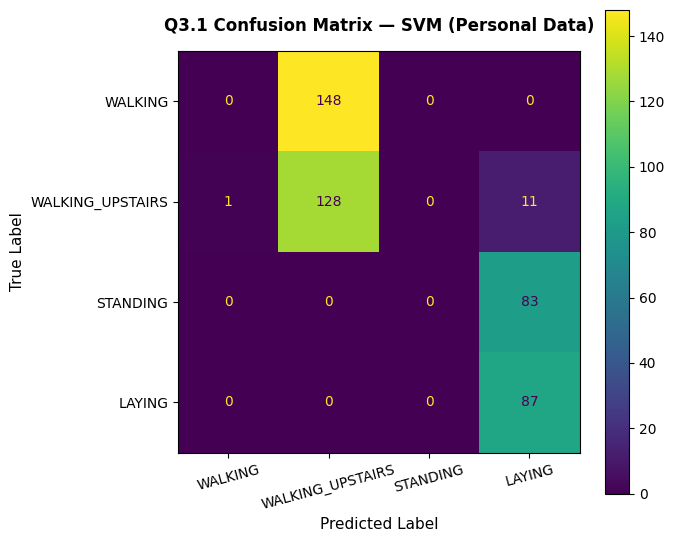



Confusion Matrix (raw counts):
Labels: ['WALKING', 'WALKING_UPSTAIRS', 'STANDING', 'LAYING']
[[  0 148   0   0]
 [  1 128   0  11]
 [  0   0   0  83]
 [  0   0   0  87]]


In [66]:
# Get activity names for personal data classes only
own_labels = sorted(set(y_own_raw))
own_label_names = [ACTIVITY_LABELS[i] for i in own_labels]

# Compute the confusion matrix
cm_own = confusion_matrix(y_own_raw, y_own_pred, labels=own_labels)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_own, display_labels=own_label_names)
disp.plot(ax=ax, cmap='viridis', colorbar=True)

ax.set_title(f"Q3.1 Confusion Matrix — {best_name} (Personal Data)",
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\n")
print("Confusion Matrix (raw counts):")
print(f"Labels: {own_label_names}")
print(cm_own)

### Sub-question Q3.1

After the unit conversion (m/s^2 to g units) the accuracy improved from
19% to 46.94% and F1 macro from 7.98% to 31.62%. However the performance
is still significantly lower than the UCI HAR test set. Specifically,
the accuracy dropped from 93.66% to 46.94%, a drop of 46.71% and the
F1 macro dropped from 93.80% to 31.62%, a drop of 62.18%.

The confusion matrix reveals two classes that are completely misclassified.

WALKING (148 samples) is predicted entirely as WALKING_UPSTAIRS with
precision, recall and F1 of 0.00, meaning it is never predicted correctly.

STANDING (83 samples) is predicted entirely as LAYING with precision,
recall and F1 of 0.00, meaning it is never predicted correctly.

LAYING (87 samples) is classified perfectly (87/87). The reason is that
LAYING has a very distinctive signal regardless of phone orientation.

WALKING_UPSTAIRS (140 samples) is mostly correct (128/140). The reason
is that WALKING_UPSTAIRS has enough dynamic movement to remain partially
distinguishable.

As described in Q0.2, the bias introduced unintentionally is that our
personal data was recorded with the phone held in the hand pointing
downward, while in the UCI HAR dataset the recordings were made with
the phone placed on the waist. This difference in phone position likely
adds noise to the sensor readings and contributes to the remaining
misclassifications.

**Extra observation:** As mentioned in Q0.2 the personal dataset is imbalanced with WALKING and WALKING_UPSTAIRS having more windows than STANDING and LAYING.However looking at the confusion matrix this imbalance does not affect the results at all because LAYING which has only 87 samples is classified perfectly while WALKING which has 148 samples is classified completely wrong. Therefore we can conclude with certainty that the imbalanced dataset that we have does not affect the results at all.

### Sub-question Q3.2

The 22 point accuracy drop is a classic example of distribution shift.
The possible causes are:

1. Different fraud patterns: fraudsters in the new market use different
techniques than those in Western Europe so the model does not recognize
them because it has never seen during training

2. Different transaction scale: the typical amount spent per transaction
differs between markets due to differences in cost of living and purchasing power.
Features based on transaction amounts will therefore have completely different
distributions in the new market compared to what the model was trained on.

3. Different infrastructure: the new market may use different payment systems
and banking systems than Western Europe. Because the model was trained on
Western European infrastructure it does not recognize the patterns produced
by a completely different payment ecosystem in the new market.

**Before each new installation we should:**

1. Compare feature distributions between the original market and the
new market using histograms and divergence scores to identify which
features differ the most and understand the magnitude of the shift
before deploying the model.

2. Check if the class balance between fraud and legitimate transactions
is similar in both markets, since a very different fraud rate in the
new market can significantly affect model performance.

3. Evaluate the model on a labeled sample of data from the new market
before full deployment to get a realistic estimate of the expected
performance and decide if it is acceptable for production use.

4. If the performance drop is unacceptable, collect labeled data from
the new market and retrain or fine-tune the model on the new
distribution before deployment.



## 3.2 Distribution shift analysis

In [67]:
def plot_feature_histogram_shift(feature_name, feature_names, X_UCI_HAR, X_own):

    feat_idx = feature_names.index(feature_name)

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.hist(X_UCI_HAR[:, feat_idx], bins=35, density=True,
            alpha=0.6, color='steelblue', label='UCI HAR', histtype='stepfilled')

    ax.hist(X_own[:, feat_idx], bins=35, density=True,
            alpha=0.6, color='tomato', label='Our data', histtype='stepfilled')

    ax.set_title(feature_name, fontsize=12)
    ax.set_xlabel('Value', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

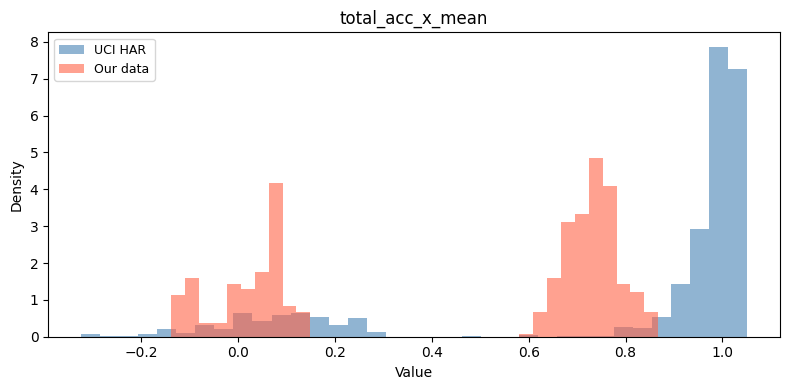

In [68]:
plot_feature_histogram_shift('total_acc_x_mean', feature_names, X_test_features, X_own_features)

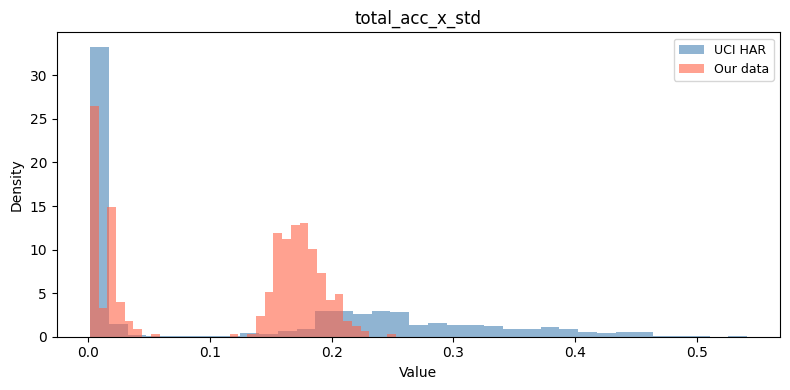

In [69]:
plot_feature_histogram_shift('total_acc_x_std', feature_names, X_test_features, X_own_features)

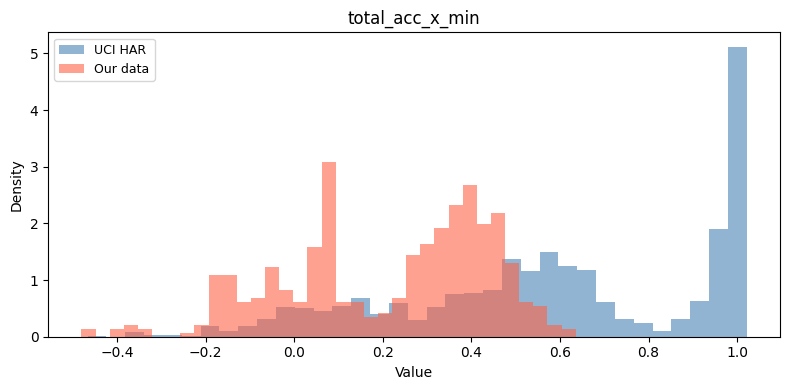

In [70]:
plot_feature_histogram_shift('total_acc_x_min', feature_names, X_test_features, X_own_features)

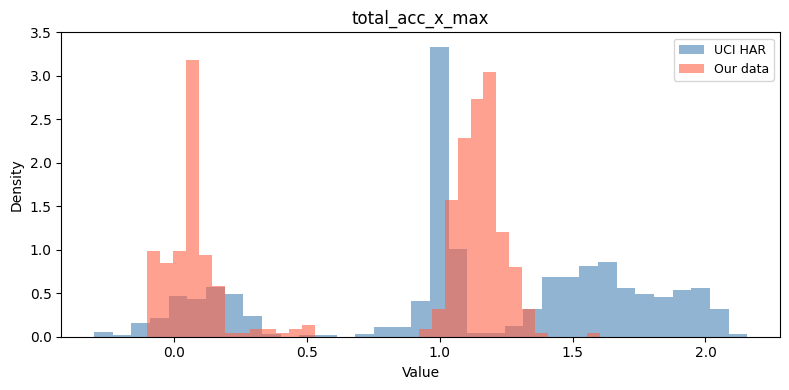

In [71]:
plot_feature_histogram_shift('total_acc_x_max', feature_names, X_test_features, X_own_features)

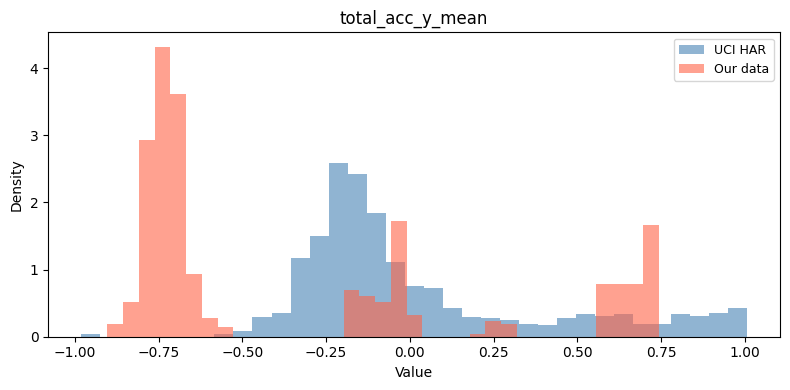

In [72]:
plot_feature_histogram_shift('total_acc_y_mean', feature_names, X_test_features, X_own_features)

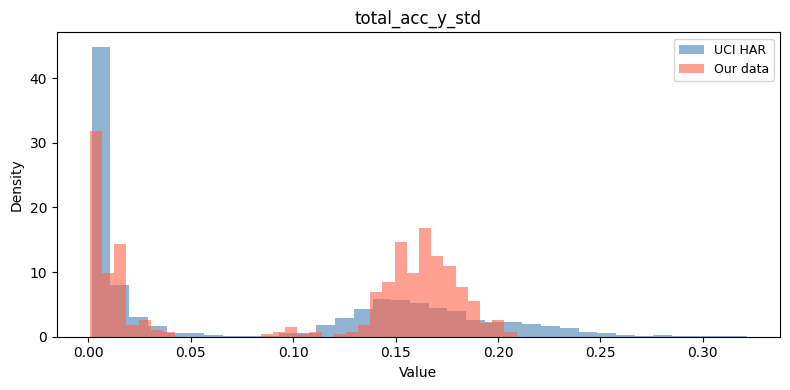

In [73]:
plot_feature_histogram_shift('total_acc_y_std', feature_names, X_test_features, X_own_features)

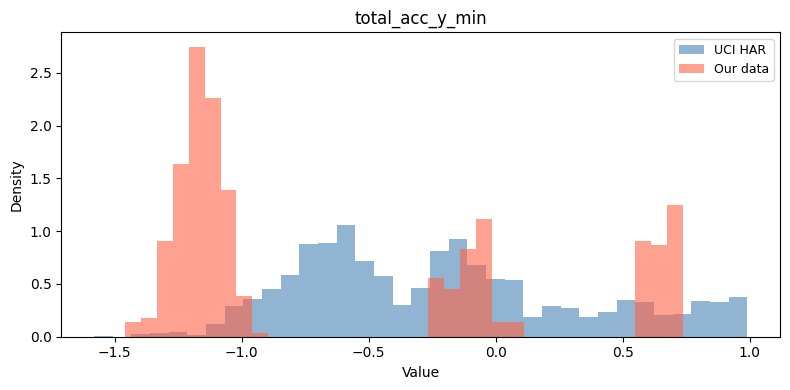

In [74]:
plot_feature_histogram_shift('total_acc_y_min', feature_names, X_test_features, X_own_features)

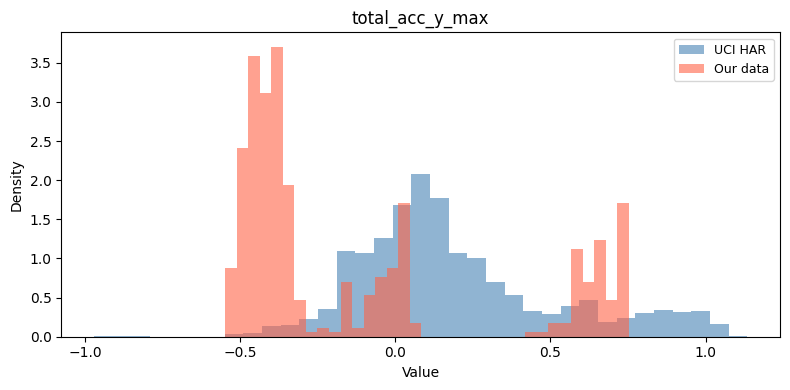

In [75]:
plot_feature_histogram_shift('total_acc_y_max', feature_names, X_test_features, X_own_features)

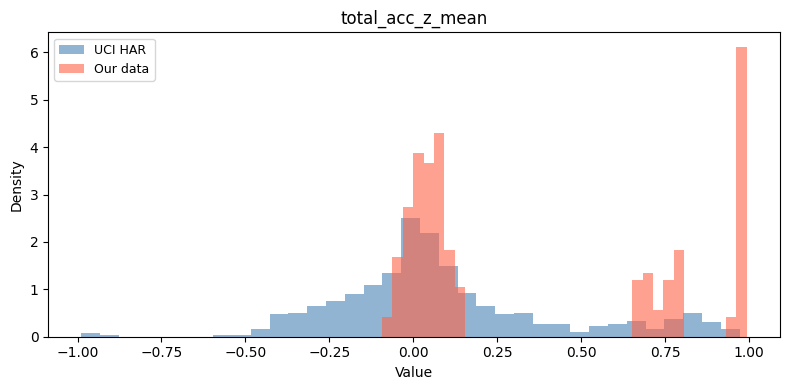

In [76]:
plot_feature_histogram_shift('total_acc_z_mean', feature_names, X_test_features, X_own_features)

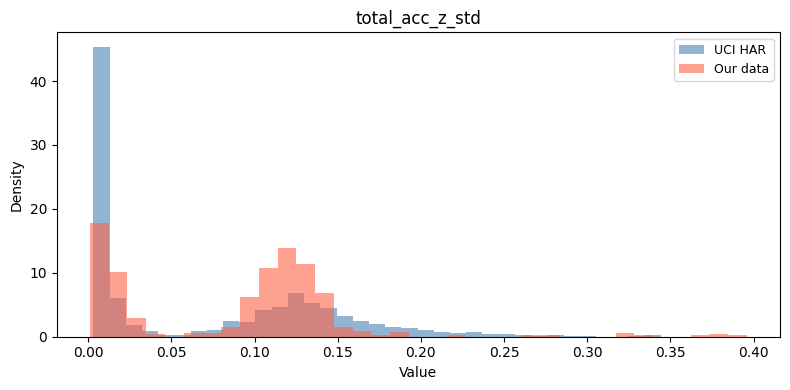

In [77]:
plot_feature_histogram_shift('total_acc_z_std', feature_names, X_test_features, X_own_features)

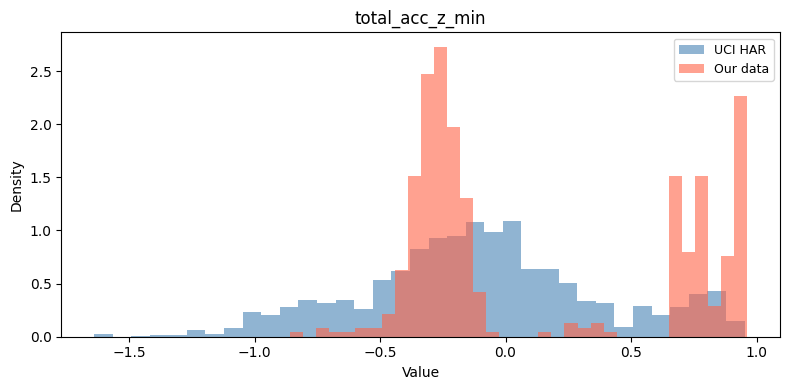

In [78]:
plot_feature_histogram_shift('total_acc_z_min', feature_names, X_test_features, X_own_features)

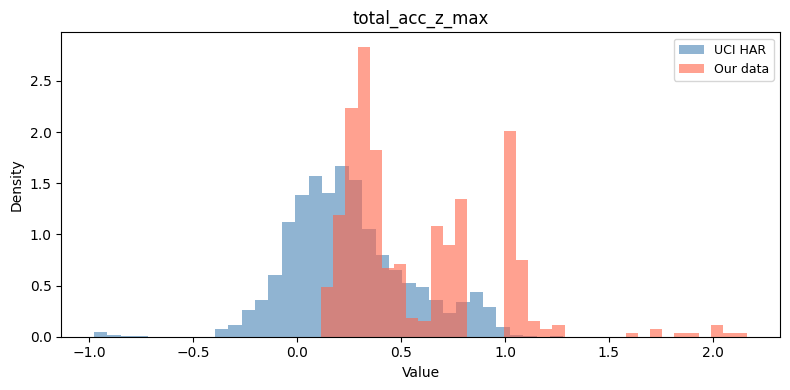

In [79]:
plot_feature_histogram_shift('total_acc_z_max', feature_names, X_test_features, X_own_features)

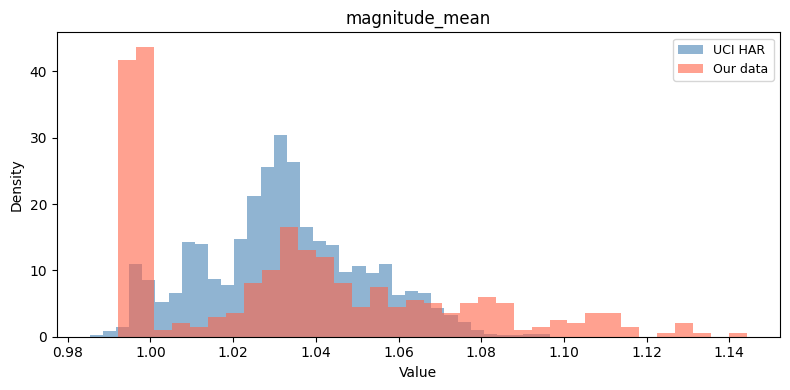

In [80]:
plot_feature_histogram_shift('magnitude_mean', feature_names, X_test_features, X_own_features)

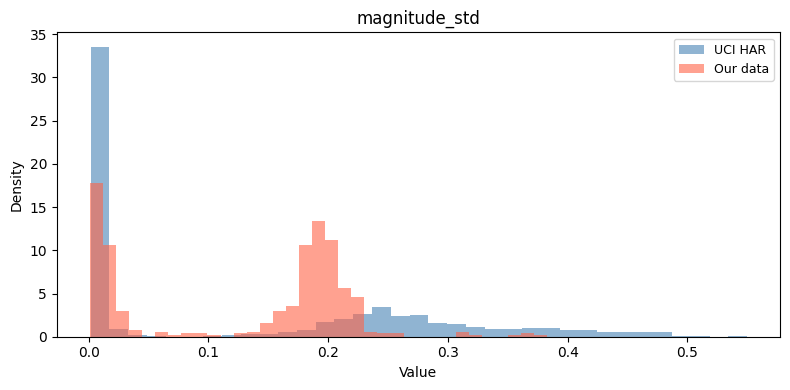

In [81]:
plot_feature_histogram_shift('magnitude_std', feature_names, X_test_features, X_own_features)

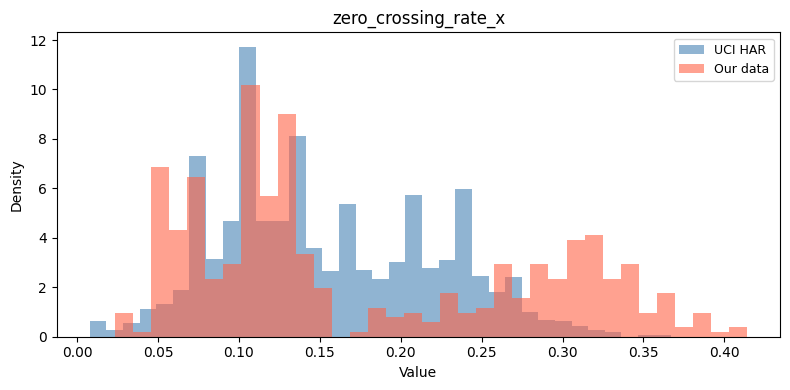

In [82]:
plot_feature_histogram_shift('zero_crossing_rate_x', feature_names, X_test_features, X_own_features)

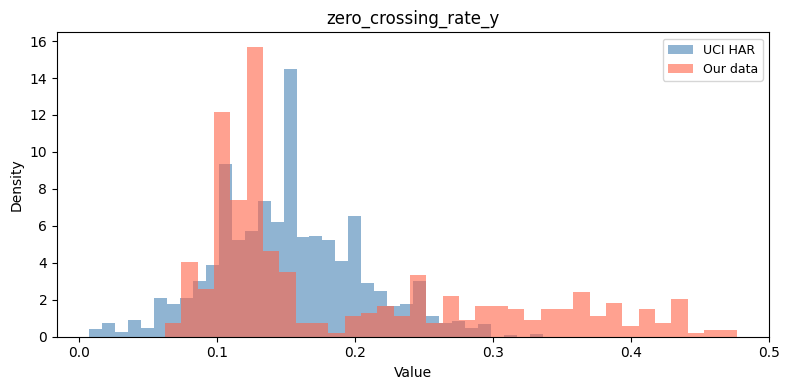

In [83]:
plot_feature_histogram_shift('zero_crossing_rate_y', feature_names, X_test_features, X_own_features)

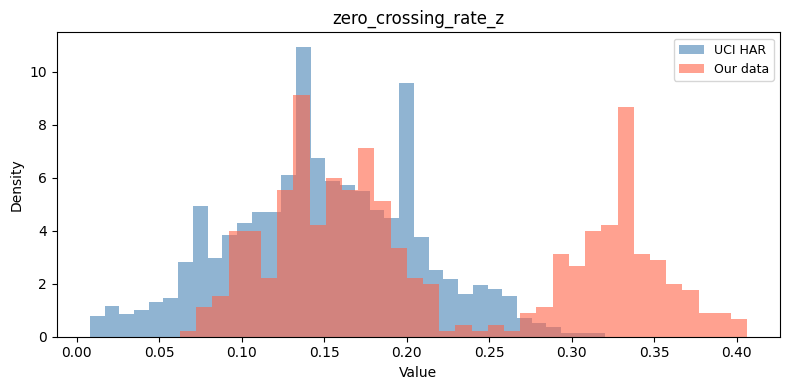

In [84]:
plot_feature_histogram_shift('zero_crossing_rate_z', feature_names, X_test_features, X_own_features)

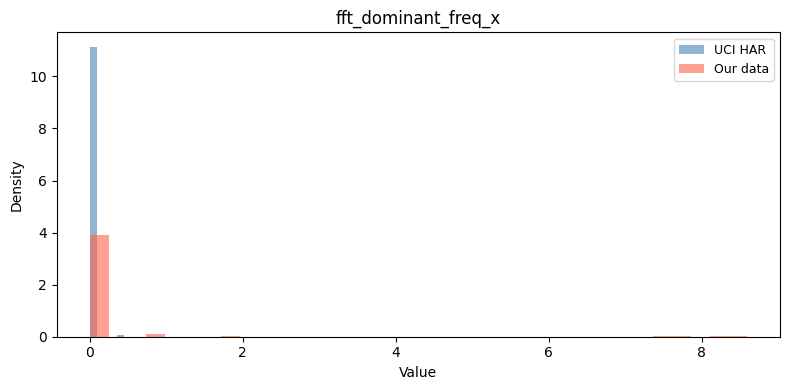

In [85]:
plot_feature_histogram_shift('fft_dominant_freq_x', feature_names, X_test_features, X_own_features)

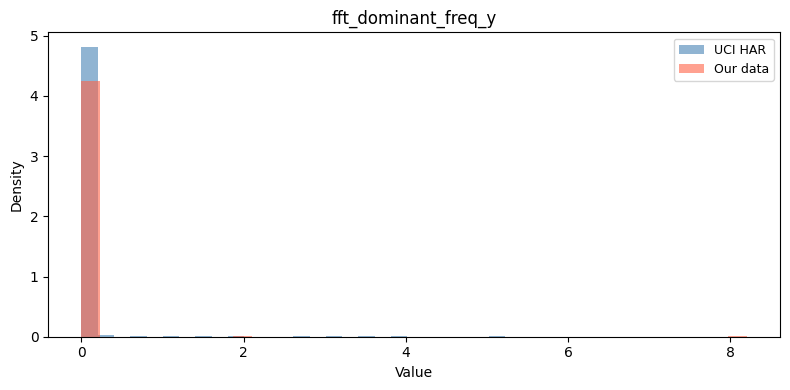

In [86]:
plot_feature_histogram_shift('fft_dominant_freq_y',   feature_names, X_test_features, X_own_features)

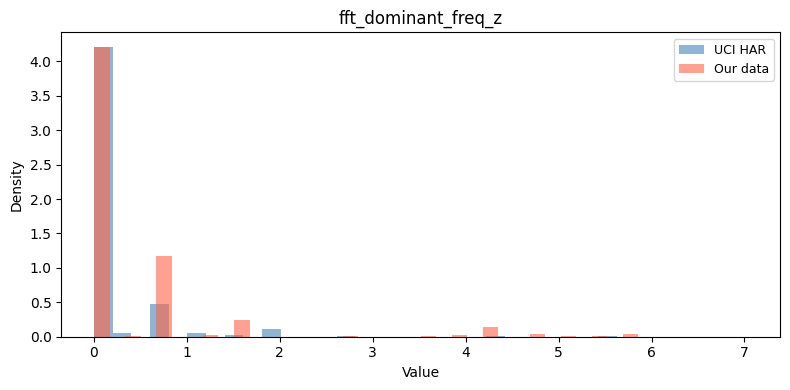

In [87]:
plot_feature_histogram_shift('fft_dominant_freq_z',   feature_names, X_test_features, X_own_features)

In [88]:
deviation_scores = []

for i, feature_name in enumerate(feature_names):
    uci_values = X_test_features[:, i]
    own_values = X_own_features[:, i]

    deviation = abs(uci_values.mean() - own_values.mean()) / uci_values.std()
    deviation_scores.append((feature_name, uci_values.mean(), own_values.mean(), deviation))

deviation_scores.sort(key=lambda x: x[3], reverse=True)


print(f"{'Rank':<6} {'Feature':<25} {'Mean UCI HAR':>12} {'Mean Own':>10} {'Deviation':>10}")
print("-" * 68)
for rank, (name, mean_uci, mean_own, dev) in enumerate(deviation_scores, 1):
    print(f"{rank:<6} {name:<25} {mean_uci:>12.4f} {mean_own:>10.4f} {dev:>10.4f}")

Rank   Feature                   Mean UCI HAR   Mean Own  Deviation
--------------------------------------------------------------------
1      fft_dominant_freq_x             0.0040     0.1578     1.8253
2      zero_crossing_rate_z            0.1491     0.2166     1.1800
3      total_acc_z_max                 0.2466     0.5732     1.1011
4      total_acc_x_min                 0.5904     0.2135     1.0824
5      total_acc_x_mean                0.8110     0.4515     0.9900
6      total_acc_y_max                 0.1904    -0.1218     0.9648
7      total_acc_y_mean                0.0217    -0.3242     0.9269
8      total_acc_z_mean                0.0869     0.3620     0.8318
9      zero_crossing_rate_y            0.1513     0.1953     0.8279
10     total_acc_y_min                -0.2170    -0.6025     0.6997
11     total_acc_x_max                 1.1350     0.7272     0.6755
12     total_acc_z_min                -0.1011     0.1395     0.5066
13     fft_dominant_freq_z             0.1848  

### Sub-question Q3.3

**Which features deviate the most between the Kaggle dataset and our own data ?**

The five features with the highest deviation scores are fft_dominant_freq_x (1.83), zero_crossing_rate_z (1.18), total_acc_z_max (1.10), total_acc_x_min (1.08) and total_acc_x_mean (0.99).

The dominant external factor explaining the shift is phone position. From the UCI HAR data we can confirm that with the phone on the waist gravity falls almost entirely on the x axis because the total_acc_x_mean = 0.80 (close to 1g), total_acc_y_mean = 0.02 (close to 0) and total_acc_z_mean = 0.09 (close to 0). We use the mean features to confirm this because the mean captures the static component of acceleration i.e. gravity. Since gravity is a constant force, it shows up in the mean rather than in the std, min or max which capture movement and variability. This confirms that the waist position means the phone is horizontal with the x axis pointing upward, capturing almost all of the 1g gravitational force. When the phone was held in hand pointing downward, gravity shifted away from the x axis toward the z axis confirmed by total_acc_x_mean dropping from 0.8 to 0.45 and total_acc_z_mean increasing from 0.09 to 0.36.

<br>

Additional factors that contributed to a lesser extent include different person (different height, weight and walking style) and different phone sensor.

<br>


| Feature Name | Mean (Kaggle) | Mean (Our data) | Observations |
|---|---|---|---|
| fft_dominant_freq_x | 0.004 | 0.158 | Large increase, std exploded from 0.08 to 1.03 |
| zero_crossing_rate_z | 0.149 | 0.217 | Moderate increase, new cluster at 0.30-0.35 absent in UCI HAR |
| total_acc_z_max | 0.247 | 0.573 | Large increase due to gravity redistribution toward z axis when phone moved from waist to hand |
| total_acc_x_min | 0.590 | 0.214 | Large decrease due to gravity leaving x axis when phone moved from waist to hand |
| total_acc_x_mean | 0.811 | 0.452 | Large decrease due to gravity leaving x axis when phone moved from waist to hand |



### Sub-question Q3.4

**Do the features with the largest deviation also account for the most errors ?**

No. The features with the largest deviation scores are not the ones responsible for the most errors. fft_dominant_freq_x (deviation 1.83) and zero_crossing_rate_z (deviation 1.18) have the highest deviation but as shown in Section 1.3 both are poor separating features i.e. all 6 classes overlap completely. Since the model never relied on these features to make decisions, even a large shift in them has no impact on the predictions.
<br> <br>
The features that actually caused the errors for example are total_acc_x_min (deviation 1.08) and total_acc_x_mean (deviation 0.99). I chose these two specifically because as shown in Section 1.3, the total_acc_x_mean is separating the LAYING is alone on the left while all other classes cluster tightly on the right and total_acc_x_min clearly separates SITTING and STANDING from WALKING activities. Both features are directly tied to the x axis which as we confirmed captures almost all of gravity (0.80g) when the phone is on the waist. When the phone moved to hand, gravity left the x axis completely because as we saw the total_acc_x_mean dropped from 0.8 to 0.5 and total_acc_x_min dropped from 0.6 to 0.2. This means the x axis values that the model learned to associate with STANDING in UCI HAR simply no longer appear in our data, making STANDING unrecognizable to the model and contributing to a great extent to it being misclassified as LAYING with 0% recall in Q3.1.

<br>

**Which one would you replace first ?**

I would replace total_acc_x_mean first because it combines the worst of both worlds it shifted dramatically (deviation 0.99) AND it is a strong separating feature that the model relied on. The root cause is that it is completely phone position dependent it only captures gravity correctly when the phone is on the waist. A better alternative is magnitude_mean (deviation 0.03) which is already in our feature set, is completely stable because it combines all 3 axes (sqrt(x^2 + y^2 + z^2)) and captures movement intensity regardless of how the phone is held making total_acc_x_mean unnecessary.

## 3.3 Improvement Strategies

## **Intervention 1**

In [89]:
# Split own data 50/50
X_own_train, X_own_test, y_own_train, y_own_test = train_test_split(
    X_own_scaled, y_own_raw,
    test_size=0.50, random_state=42
)


best_params = {'C': 100, 'kernel': 'rbf'}

# Kaggle train + own-train
X_combined = np.vstack([X_train_scaled, X_own_train])
y_combined = np.concatenate([y_train, y_own_train])


svm_a = SVC(C=best_params['C'], kernel=best_params['kernel'], random_state=42)
svm_a.fit(X_combined, y_combined)

acc_a_own = accuracy_score(y_own_test, svm_a.predict(X_own_test))
f1_a_own = f1_score(y_own_test, svm_a.predict(X_own_test), average='macro')
acc_a_kaggle = accuracy_score(y_test, svm_a.predict(X_test_scaled))
f1_a_kaggle = f1_score(y_test, svm_a.predict(X_test_scaled), average='macro')

print("Intervention 1(a): Kaggle + own train")
print(f"Own test Accuracy: {acc_a_own*100:.2f}% and F1 macro: {f1_a_own*100:.2f}%")
print(f"Kaggle test Accuracy: {acc_a_kaggle*100:.2f}% and F1 macro: {f1_a_kaggle*100:.2f}%")

Intervention 1(a): Kaggle + own train
Own test Accuracy: 96.94% and F1 macro: 96.87%
Kaggle test Accuracy: 93.72% and F1 macro: 93.84%


### **Intervention 1(a) (Kaggle + own-train) — Results and Analysis:**

Adding 229 samples (50% of our 458 personal recordings covering 4 activities (WALKING, WALKING_UPSTAIRS, STANDING, LAYING)) to the Kaggle training set significantly improved performance on our own data, jumping from 46.94% to 96.94% accuracy (+ 50%) and from 31.62% to 96.87% F1 macro
(+ 65.25%). At the same time the Kaggle test accuracy and F1 macro remained essentially unchanged (93.66% -> 93.72%, F1: 93.80% -> 93.84%), meaning that adding our personal samples did not negatively affect the Kaggle performance. This means that when we held the phone in hand instead of in the waist some values shifted, as seen in the histograms of §3.2, but the differences between these two datasets are not extreme enough to confuse the model on the Kaggle test set. This shows that even a small number of personal samples was enough to teach the model the characteristics of our dataset i.e. the main problem was that the phone was held in hand instead of on the waist

In [90]:
# Only own train
svm_b = SVC(C=best_params['C'], kernel=best_params['kernel'], random_state=42)
svm_b.fit(X_own_train, y_own_train)

acc_b_own = accuracy_score(y_own_test, svm_b.predict(X_own_test))
f1_b_own = f1_score(y_own_test, svm_b.predict(X_own_test), average='macro')
acc_b_kaggle = accuracy_score(y_test, svm_b.predict(X_test_scaled))
f1_b_kaggle = f1_score(y_test, svm_b.predict(X_test_scaled), average='macro')

print("Intervention 1(b): only own train")
print(f"Own test Accuracy: {acc_b_own*100:.2f}% and F1 macro: {f1_b_own*100:.2f}%")
print(f"Kaggle test Accuracy: {acc_b_kaggle*100:.2f}% and F1 macro: {f1_b_kaggle*100:.2f}%")

Intervention 1(b): only own train
Own test Accuracy: 98.25% and F1 macro: 98.56%
Kaggle test Accuracy: 28.61% and F1 macro: 21.98%


### **Intervention 1(b) (only own-train) — Results and Analysis:**

Training only on 229 personal samples gave high accuracy and F1 macro on
own-test (98.25% accuracy, 98.56% F1) because the model was trained and
tested on the same 4 activities and on the same type of data (our personal
recordings), not on the UCI HAR type of data. However the Kaggle test accuracy and F1 macro collapsed to 28.61% accuracy and 21.98% F1 macro respectively, which is even worse than the naive baseline. This happened because the model was trained on too few samples covering only 4 out of 6 activities, meaning it had never seen WALKING_DOWNSTAIRS and SITTING at all during training and therefore had no ability to predict them correctly. And because it was trained on so few samples for the remaining activities and had never seen any UCI HAR type of data during training, it completely overfit to our personal data and lost all ability to generalize to the UCI HAR dataset.

## **Intervention 2**

In [91]:
# Remove fft_dominant_freq_x (highest deviation feature)
drop_feat = 'fft_dominant_freq_x'
drop_idx  = feature_names.index(drop_feat)

# Remove from all sets
X_train_drop = np.delete(X_train_scaled, drop_idx, axis=1)
X_test_drop = np.delete(X_test_scaled, drop_idx, axis=1)
X_own_drop = np.delete(X_own_scaled, drop_idx, axis=1)

svm_drop = SVC(C=best_params['C'], kernel=best_params['kernel'], random_state=42)
svm_drop.fit(X_train_drop, y_train)

acc_drop_kaggle = accuracy_score(y_test, svm_drop.predict(X_test_drop))
f1_drop_kaggle = f1_score(y_test, svm_drop.predict(X_test_drop), average='macro')

acc_drop_own = accuracy_score(y_own_raw, svm_drop.predict(X_own_drop))
f1_drop_own = f1_score(y_own_raw, svm_drop.predict(X_own_drop), average='macro')

print("Intervention 2: remove fft_dominant_freq_x (highest deviation feature)")
print(f"Kaggle test Accuracy: {acc_drop_kaggle*100:.2f}% and F1 macro: {f1_drop_kaggle*100:.2f}%")
print(f"Own data Accuracy: {acc_drop_own*100:.2f}% and F1 macro: {f1_drop_own*100:.2f}%")

Intervention 2: remove fft_dominant_freq_x (highest deviation feature)
Kaggle test Accuracy: 93.53% and F1 macro: 93.66%
Own data Accuracy: 46.94% and F1 macro: 25.39%


### **Intervention 2 (remove fft_dominant_freq_x) — Results and Analysis:**


Removing fft_dominant_freq_x, the feature with the highest deviation
(1.8253) between the UCI HAR dataset and our personal data, did not
improve performance on our own data (accuracy stayed at 46.94%, F1 macro
dropped from 31.62% to 25.39%) and also slightly hurt the Kaggle test set
(accuracy: 93.66% -> 93.53%, F1 macro: 93.80% -> 93.66%).

This confirms that the distribution shift is not caused by a single
feature but by the overall difference in phone placement between our
recordings (hand) and the UCI HAR dataset (waist). This affects many
features simultaneously, especially all total_acc features, so
removing only one feature cannot fix the underlying problem.

### Sub-question Q3.5

In [92]:
import pandas as pd

pd.DataFrame({
    "Evaluation Scenario": [
        "Kaggle test set (§2)",
        "Own data (no retraining)",
        "Own data with Intervention 1(a) (Kaggle + own-train)",
        "Own data with Intervention 1(b) (only own-train)",
        "Own data with Intervention 2"
    ],
    "Accuracy (%)": ["93.66%", "46.94%", "96.94%", "98.25%", "46.94%"],
    "F1 macro (%)": ["93.80%", "31.62%", "96.87%", "98.56%", "25.39%"],
    "Observation": [
        "Best model SVM baseline performance on UCI HAR test set",
        "Large drop due to distribution shift caused by phone placement difference (hand vs waist)",
        "Adding 229 own samples to Kaggle training set almost completely fixed the distribution shift caused by phone placement difference (hand vs waist) without affecting Kaggle performance",
        "High accuracy and F1 on own-test but Kaggle collapsed to 28.61% accuracy and 21.98% F1 because we have  only 4 out of 6 activities in training, so WALKING_DOWNSTAIRS and SITTING were never seen and zero UCI HAR data during training caused complete overfitting to personal recordings ",
        "Removing fft_dominant_freq_x did not help since the shift caused by phone placement difference (hand vs waist) affects many features simultaneously, not just one"
    ]
})

,Evaluation Scenario,Accuracy (%),F1 macro (%),Observation
0,Kaggle test set (§2),93.66%,93.80%,Best model SVM baseline performance on UCI HAR test set
1,Own data (no retraining),46.94%,31.62%,Large drop due to distribution shift caused by phone placement difference (hand vs waist)
2,Own data with Intervention 1(a) (Kaggle + own-train),96.94%,96.87%,Adding 229 own samples to Kaggle training set almost completely fixed the distribution shift caused by phone placement difference (hand vs waist) without affecting Kaggle performance
3,Own data with Intervention 1(b) (only own-train),98.25%,98.56%,"High accuracy and F1 on own-test but Kaggle collapsed to 28.61% accuracy and 21.98% F1 because we have only 4 out of 6 activities in training, so WALKING_DOWNSTAIRS and SITTING were never seen and zero UCI HAR data during training caused complete overfitting to personal recordings"
4,Own data with Intervention 2,46.94%,25.39%,"Removing fft_dominant_freq_x did not help since the shift caused by phone placement difference (hand vs waist) affects many features simultaneously, not just one"


### Sub-question Q3.6

**Intervention 1(a) worked best**. As described in detail in the
"Intervention 1(a) (Kaggle + own-train) — Results and Analysis" section,
adding 229 personal samples to the Kaggle training set improved own data
accuracy from 46.94% to 96.94% (+50%) and F1 macro from 31.62% to 96.87%
(+65.25%) without affecting Kaggle performance (93.66% -> 93.72%,
F1: 93.80% -> 93.84%).

It helped because even a small number of personal samples was enough to teach the model the characteristics of our dataset i.e. the main problem was that the phone was held in hand instead of on the waist and as seen in the histograms of §3.2 the differences between the two datasets are not extreme enough to confuse the model on the Kaggle test set.

**Intervention 1(b)** did not generalize because the model was trained on too few samples covering only 4 out of 6 activities, meaning it had never seen WALKING_DOWNSTAIRS and SITTING at all and had never seen any UCI HAR type of data during training, causing it to completely overfit to our personal data.

**Intervention 2** did not help because the distribution shift is not caused by a single feature but by the overall phone placement difference (hand vs waist) which affects many features simultaneously, especially all total_acc features, so removing only one feature cannot fix the problem.

### Sub-question Q3.7


The most important change would be to record with the phone placed on
the waist instead of held in the hand. As confirmed in Q3.3, the root
cause of the distribution shift was the phone placement difference. With
the phone on the waist gravity falls almost entirely on the x axis
(total_acc_x_mean = 0.80 in UCI HAR) while with the phone in the hand
gravity redistributed toward the z axis (total_acc_x_mean dropped from
0.80 to 0.45 and total_acc_z_mean increased from 0.09 to 0.36),
confirming that gravity shifted away from the x axis toward the z axis
when the phone moved from the waist to the hand. This single change
would directly fix the gravity dependent features (total_acc_z_max,
total_acc_x_min, total_acc_x_mean) which are all in the top 5 highest
deviation features (rank 3, 4 and 5 respectively from the deviation
table in Q3.3) and shifted because gravity redistributed from the x
axis to the z axis. This would likely increase both accuracy and F1
macro significantly from 46.94% and 31.62% respectively, bringing them
much closer to the UCI HAR test set performance of 93.66% accuracy
and 93.80% F1 macro.

It is worth noting that the hand position was not a deliberate choice
but a consequence of the app used for recording. The Phyphox app was
used, however it stopped recording when the phone screen turned off,
making it impossible to place the phone in a pocket or on the waist,
which would have reduced the distribution shift significantly.

<br>

A secondary change although less important than the phone placement fix, would include recording in different locations and environments to add more diversity to the personal data.